In [5]:
import json
import os

import agama
import gizmo_analysis as gizmo
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import utilities as ut
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter
from scipy.stats import gaussian_kde
from sklearn.svm import SVC

agama.setUnits(mass=1, length=1, velocity=1)
units = agama.getUnits()

# plt.rc("font", family="Nimbus Roman")
plt.rc("font", family="Nimbus Roman No9 L")

SMALL_SIZE = 7
MEDIUM_SIZE = 7
BIGGER_SIZE = 7

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [6]:
sim_dir = "/Users/z5114326/Documents/simulations/"
# sim_dir = "/Volumes/Expansion/simulations/"
sim_lst = ["m12b", "m12c", "m12f", "m12i", "m12m"]

snap = 600

public_snapshot_file = sim_dir + "snapshot_times_public.txt"
pub_data = pd.read_table(public_snapshot_file, comment="#", header=None, sep=r"\s+")
pub_data.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]
timez0 = float(pub_data[pub_data["index"] == snap]["time_Gyr"].values[0])
pub_snaps = np.array(pub_data["index"])
pub_tims = np.array(pub_data["time_Gyr"])

all_data_fil = sim_dir + "/" + "m12i" + "/" + "m12i" + "_res7100/" + "snapshot_times.txt"
all_data = pd.read_table(all_data_fil, comment="#", header=None, sep=r"\s+")
all_data.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]
all_times = np.array(all_data["time_Gyr"])
all_snaps = np.array(all_data["index"])

sim_codes = sim_dir + "simulation_codes.json"
with open(sim_codes) as sim_json:
    sim_data = json.load(sim_json)

scmap = plt.get_cmap("tab10")
colors = [scmap(i) for i in np.linspace(0, 1, len(sim_lst))]
sim_colors = {sim: colors[i] for i, sim in enumerate(sim_lst)}

spin_fil = "../data/sim_data/spin_up_lbt.json"
with open(spin_fil) as spin_json:
    spin_up_lbt_dict = json.load(spin_json)

In [7]:
t600 = pub_tims[pub_snaps == 600][0]
t534 = pub_tims[pub_snaps == 534][0]
tdif = t600 - t534
t600, t534, tdif

(np.float64(13.798746883),
 np.float64(12.500601156),
 np.float64(1.2981457269999996))

# Functions

In [8]:
def gif_wrapping(
    plot_func,
    param_name,
    param_values,
    gif_path,
    fixed_kwargs=None,
    interval=200,
    dpi=150,
    figsize=(8, 6),
):
    """Generic animation wrapper."""

    fixed_kwargs = fixed_kwargs or {}

    fig, ax = plt.subplots(figsize=figsize)

    def update(value):
        kwargs = fixed_kwargs.copy()
        kwargs[param_name] = value
        plot_func(ax=ax, **kwargs)
        return (ax,)

    anim = FuncAnimation(
        fig,
        update,
        frames=param_values,
        interval=interval,
        blit=False,
    )

    fps = max(1, int(1000 / interval))  # avoid fps=0
    anim.save(gif_path, writer=PillowWriter(fps=fps), dpi=dpi)

    plt.close(fig)


In [9]:
def draw_contour(ax, Z_list, color, XX, YY, cont_level):
    if len(Z_list) == 0:
        return

    Z_avg = np.mean(Z_list, axis=0)
    Z_avg[XX <= 4] = 0

    Zf = Z_avg.ravel()
    idx = np.argsort(Zf)[::-1]
    Zs = Zf[idx]

    cdf = np.cumsum(Zs)
    cdf /= cdf[-1]

    level = Zs[np.searchsorted(cdf, cont_level)]

    ax.contour(10**XX, 10**YY, Z_avg, levels=[level], colors=color, linewidths=2)


def plot_cont_bounding_tig(ax, sim, tcut, in_msk=True, cont_level=0.95, plt_text=False):

    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"

    ax.clear()

    logx_grid = np.linspace(3, 7.2, 200)
    logy_grid = np.linspace(0, 7, 200)
    XX, YY = np.meshgrid(logx_grid, logy_grid)
    grid_positions = np.vstack([XX.ravel(), YY.ravel()])

    Z0_list = []
    Z1_list = []

    print(f"{sim} - {tcut} - {in_msk}")

    with h5py.File(ghost_file, "r") as ghost_data:
        for it_id in ghost_data.keys():
            src_dat = ghost_data[it_id]["source"]

            if in_msk:
                acc = src_dat["grpid"][()] == 0
            else:
                acc = src_dat["grpid"][()] != 0

            mfor = 10 ** src_dat["logm_tfor"][()]
            tig = src_dat["tideig.avg"][()]
            sa_msk = src_dat["sa_flag"][()] != 0

            tacc = np.array(src_dat["tacc"][()])
            tdis = np.array(src_dat["tdis"][()]).copy()
            tfor = np.array(src_dat["tfor"][()])

            tdis[tdis == -1] = np.inf

            tfor_msk = tfor <= tcut
            tdis_msk = tdis <= tcut
            tacc_msk = tacc <= tcut

            mask_common = tfor_msk & tacc_msk & acc & sa_msk

            x0 = mfor[mask_common & tdis_msk]
            y0 = tig[mask_common & tdis_msk]

            x1 = mfor[mask_common & (~tdis_msk)]
            y1 = tig[mask_common & (~tdis_msk)]

            valid0 = (x0 > 0) & (y0 > 0)
            valid1 = (x1 > 0) & (y1 > 0)

            x0, y0 = x0[valid0], y0[valid0]
            x1, y1 = x1[valid1], y1[valid1]

            log_x0 = np.log10(x0)
            log_y0 = np.log10(y0)
            log_x1 = np.log10(x1)
            log_y1 = np.log10(y1)

            isfin0 = np.isfinite(log_x0) & np.isfinite(log_y0)
            isfin1 = np.isfinite(log_x1) & np.isfinite(log_y1)

            log_x0, log_y0 = log_x0[isfin0], log_y0[isfin0]
            log_x1, log_y1 = log_x1[isfin1], log_y1[isfin1]

            if len(log_x0) > 5:
                kde0 = gaussian_kde(np.vstack([log_x0, log_y0]))
                Z0 = kde0(grid_positions).reshape(XX.shape)
                Z0 /= Z0.sum()
                Z0_list.append(Z0)

            if len(log_x1) > 5:
                kde1 = gaussian_kde(np.vstack([log_x1, log_y1]))
                Z1 = kde1(grid_positions).reshape(XX.shape)
                Z1 /= Z1.sum()
                Z1_list.append(Z1)

    col = "r" if in_msk else "b"

    draw_contour(ax, Z0_list, "grey", XX, YY, cont_level)
    draw_contour(ax, Z1_list, col, XX, YY, cont_level)

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlim(10**3.9, 10**7)
    ax.set_ylim(10**2, 5 * 10**6)

    ax.set_xlabel(r"$\mathrm{M}_{form}\ (\mathrm{M}_\odot)$")
    ax.set_ylabel(r"$\lambda_e\;(\mathrm{Gyr}^{-2})$")

    if plt_text:
        text = f"{sim}\nt = {tcut:.2f} Gyr"
        ax.text(
            0.02,
            0.92,
            text,
            transform=ax.transAxes,
            color="k",
            ha="left",
            va="center",
            bbox=dict(facecolor="white", edgecolor="white"),
        )

        surv = Line2D([0], [0], color=col, linewidth=2, label="Surviving Population")
        disr = Line2D([0], [0], color="grey", linewidth=2, label="Disrupted Population")
        ax.legend(handles=[surv, disr], frameon=False)


In [10]:
def get_kde_grids_eig(sim, tcut, in_msk=True):

    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"

    logx_grid = np.linspace(3, 7.2, 200)
    logy_grid = np.linspace(0, 7, 200)
    XX, YY = np.meshgrid(logx_grid, logy_grid)
    grid_positions = np.vstack([XX.ravel(), YY.ravel()])

    Z0_list = []
    Z1_list = []

    print(f"{sim} - {tcut} - {in_msk}")

    with h5py.File(ghost_file, "r") as ghost_data:
        for it_id in ghost_data.keys():
            src_dat = ghost_data[it_id]["source"]

            if in_msk:
                acc = src_dat["grpid"][()] == 0
            else:
                acc = src_dat["grpid"][()] != 0

            mfor = 10 ** src_dat["logm_tfor"][()]
            tig = src_dat["tideig.avg"][()]
            sa_msk = src_dat["sa_flag"][()] != 0

            tacc = np.array(src_dat["tacc"][()])
            tdis = np.array(src_dat["tdis"][()]).copy()
            tfor = np.array(src_dat["tfor"][()])

            tdis[tdis == -1] = np.inf

            tfor_msk = tfor <= tcut
            tdis_msk = tdis <= tcut
            tacc_msk = tacc <= tcut

            mask_common = tfor_msk & tacc_msk & acc & sa_msk

            x0 = mfor[mask_common & tdis_msk]
            y0 = tig[mask_common & tdis_msk]

            x1 = mfor[mask_common & (~tdis_msk)]
            y1 = tig[mask_common & (~tdis_msk)]

            valid0 = (x0 > 0) & (y0 > 0)
            valid1 = (x1 > 0) & (y1 > 0)

            x0, y0 = x0[valid0], y0[valid0]
            x1, y1 = x1[valid1], y1[valid1]

            log_x0 = np.log10(x0)
            log_y0 = np.log10(y0)
            log_x1 = np.log10(x1)
            log_y1 = np.log10(y1)

            isfin0 = np.isfinite(log_x0) & np.isfinite(log_y0)
            isfin1 = np.isfinite(log_x1) & np.isfinite(log_y1)

            log_x0, log_y0 = log_x0[isfin0], log_y0[isfin0]
            log_x1, log_y1 = log_x1[isfin1], log_y1[isfin1]

            if len(log_x0) > 5:
                kde0 = gaussian_kde(np.vstack([log_x0, log_y0]))
                Z0 = kde0(grid_positions).reshape(XX.shape)
                Z0 /= Z0.sum()
                Z0_list.append(Z0)

            if len(log_x1) > 5:
                kde1 = gaussian_kde(np.vstack([log_x1, log_y1]))
                Z1 = kde1(grid_positions).reshape(XX.shape)
                Z1 /= Z1.sum()
                Z1_list.append(Z1)

    return XX, YY, Z0_list, Z1_list


def compute_full_diagnostics(sim, tcut, in_msk=True, cont_level=0.95):

    XX, YY, Z0_list, Z1_list = get_kde_grids_eig(sim, tcut, in_msk)

    if len(Z0_list) == 0 or len(Z1_list) == 0:
        return np.nan, np.nan, np.nan, np.nan, np.nan

    # --- Average KDEs ---
    Z0_avg = np.mean(Z0_list, axis=0)
    Z1_avg = np.mean(Z1_list, axis=0)

    # --- Apply same cut as plots ---
    Z0_avg[XX <= 4] = 0
    Z1_avg[XX <= 4] = 0

    if Z0_avg.sum() == 0 or Z1_avg.sum() == 0:
        return np.nan, np.nan, np.nan, np.nan, np.nan

    # --- Normalize ---
    Z0_avg /= Z0_avg.sum()
    Z1_avg /= Z1_avg.sum()

    # ============================
    # 1. GLOBAL OVERLAP
    # ============================
    pdf_overlap = np.sum(np.minimum(Z0_avg, Z1_avg))

    # ============================
    # 2. EXCLUSIVE REGIONS (KEY)
    # ============================
    exclusive_survivor = np.sum(np.clip(Z1_avg - Z0_avg, 0, None))
    exclusive_disrupted = np.sum(np.clip(Z0_avg - Z1_avg, 0, None))

    # ============================
    # 3. PURITY (BOUNDARY EMERGENCE)
    # ============================
    # purity = Z1_avg / (Z1_avg + Z0_avg + 1e-12)

    # frac_pure = np.sum((purity > 0.9) | (purity < 0.1)) / purity.size

    density = Z0_avg + Z1_avg
    purity = Z1_avg / (density + 1e-12)

    weights = density / density.sum()

    frac_pure_weighted = np.sum(weights * ((purity > 0.9) | (purity < 0.1)))
    frac_pure = frac_pure_weighted

    # ============================
    # 4. CONTOUR OVERLAP (VISUAL MATCH)
    # ============================
    def contour_mask(Z):
        Zf = Z.ravel()
        idx = np.argsort(Zf)[::-1]
        Zs = Zf[idx]

        cdf = np.cumsum(Zs)
        cdf /= cdf[-1]

        level = Zs[np.searchsorted(cdf, cont_level)]
        return Z >= level

    mask0 = contour_mask(Z0_avg)
    mask1 = contour_mask(Z1_avg)

    dx = XX[0, 1] - XX[0, 0]
    dy = YY[1, 0] - YY[0, 0]
    cell_area = dx * dy

    intersection = np.sum((mask0 & mask1) * cell_area)
    union = np.sum((mask0 | mask1) * cell_area)

    contour_overlap = intersection / union if union > 0 else np.nan

    return pdf_overlap, contour_overlap, exclusive_survivor, exclusive_disrupted, frac_pure

In [11]:
def get_semi_major(src_dat, pot_snp, star_ic, dark_ic):
    pidxs_600 = src_dat["pidx_snap600"][()]
    ptypes = np.array([ptype.decode("utf-8") for ptype in src_dat["ptype"]])

    semi_major = np.zeros(len(pidxs_600))

    for ptype in ("star", "dark"):
        mask = ptypes == ptype
        ptype_pidx = pidxs_600[mask]

        if ptype == "star":
            ic = star_ic[ptype_pidx]
        elif ptype == "dark":
            ic = dark_ic[ptype_pidx]

        radii_pos = pot_snp.Rperiapo(ic)
        rse_arr = (radii_pos[:, 0] + radii_pos[:, 1]) / 2

        semi_major[mask] = rse_arr

    return semi_major


def get_kde_grids_semi_major(sim, snap, pot_snp, star_ic, dark_ic, in_msk=True):

    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"

    logx_grid = np.linspace(3, 7.2, 200)
    logy_grid = np.linspace(-1, 5, 200)
    XX, YY = np.meshgrid(logx_grid, logy_grid)
    grid_positions = np.vstack([XX.ravel(), YY.ravel()])

    Z0_list = []
    Z1_list = []

    tcut = pub_data[pub_data["index"] == snap]["time_Gyr"].values[0]

    print(f"{sim} - {snap} - {in_msk}")

    with h5py.File(ghost_file, "r") as ghost_data:
        for it_id in ghost_data.keys():
            src_dat = ghost_data[it_id]["source"]

            if in_msk:
                acc = src_dat["grpid"][()] == 0
            else:
                acc = src_dat["grpid"][()] != 0

            mfor = 10 ** src_dat["logm_tfor"][()]
            smaj = get_semi_major(src_dat, pot_snp, star_ic, dark_ic)
            sa_msk = src_dat["sa_flag"][()] != 0

            tacc = np.array(src_dat["tacc"][()])
            tdis = np.array(src_dat["tdis"][()]).copy()
            tfor = np.array(src_dat["tfor"][()])

            tdis[tdis == -1] = np.inf

            tfor_msk = tfor <= tcut
            tdis_msk = tdis <= tcut
            tacc_msk = tacc <= tcut

            mask_common = tfor_msk & tacc_msk & acc & sa_msk

            x0 = mfor[mask_common & tdis_msk]
            y0 = smaj[mask_common & tdis_msk]

            x1 = mfor[mask_common & (~tdis_msk)]
            y1 = smaj[mask_common & (~tdis_msk)]

            valid0 = (x0 > 0) & (y0 > 0)
            valid1 = (x1 > 0) & (y1 > 0)

            x0, y0 = x0[valid0], y0[valid0]
            x1, y1 = x1[valid1], y1[valid1]

            log_x0 = np.log10(x0)
            log_y0 = np.log10(y0)
            log_x1 = np.log10(x1)
            log_y1 = np.log10(y1)

            isfin0 = np.isfinite(log_x0) & np.isfinite(log_y0)
            isfin1 = np.isfinite(log_x1) & np.isfinite(log_y1)

            log_x0, log_y0 = log_x0[isfin0], log_y0[isfin0]
            log_x1, log_y1 = log_x1[isfin1], log_y1[isfin1]

            if len(log_x0) > 5:
                kde0 = gaussian_kde(np.vstack([log_x0, log_y0]))
                Z0 = kde0(grid_positions).reshape(XX.shape)
                Z0 /= Z0.sum()
                Z0_list.append(Z0)

            if len(log_x1) > 5:
                kde1 = gaussian_kde(np.vstack([log_x1, log_y1]))
                Z1 = kde1(grid_positions).reshape(XX.shape)
                Z1 /= Z1.sum()
                Z1_list.append(Z1)

    return XX, YY, Z0_list, Z1_list

In [12]:
def to_json_serializable(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, dict):
        return {k: to_json_serializable(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [to_json_serializable(v) for v in obj]
    elif isinstance(obj, (np.integer, np.floating)):
        return obj.item()
    else:
        return obj

In [57]:
def average_cont(Z_list, XX, YY):
    if len(Z_list) == 0:
        return

    Z_avg = np.mean(Z_list, axis=0)
    Z_avg[XX <= 4] = 0

    return Z_avg, XX, YY


def plot_averages(ax, Z_avg, XX, YY, color, cont_level, lw=2):
    Zf = Z_avg.ravel()
    idx = np.argsort(Zf)[::-1]
    Zs = Zf[idx]

    cdf = np.cumsum(Zs)
    cdf /= cdf[-1]

    if not isinstance(cont_level, list):
        cont_level = [cont_level]

    for clevel in cont_level:
        level = Zs[np.searchsorted(cdf, clevel)]
        ax.contour(10**XX, 10**YY, Z_avg, levels=[level], colors=color, linewidths=lw, zorder=0)

In [14]:
def get_boundary(ghost_data, pot_snp, star_ic, dark_ic, tcut, in_msk, age_cut):

    split_dict = {}
    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]

        if in_msk:
            acc = src_dat["grpid"][()] == 0
        else:
            acc = src_dat["grpid"][()] != 0

        mfor = 10 ** src_dat["logm_tfor"][()]
        smaj = get_semi_major(src_dat, pot_snp, star_ic, dark_ic)
        sa_msk = src_dat["sa_flag"][()] != 0

        tacc = np.array(src_dat["tacc"][()])
        tdis = np.array(src_dat["tdis"][()]).copy()
        tfor = np.array(src_dat["tfor"][()])

        if age_cut is not None:
            tage = tcut - tfor
            tage_msk = tage > age_cut
        else:
            tage_msk = np.ones(len(tfor), dtype=bool)

        tdis[tdis == -1] = np.inf

        tfor_msk = tfor <= tcut
        tdis_msk = tdis <= tcut
        tacc_msk = tacc <= tcut

        mask_common = tfor_msk & tacc_msk & acc & sa_msk & tage_msk

        x0 = mfor[mask_common & tdis_msk]  # disrupted
        y0 = smaj[mask_common & tdis_msk]

        x1 = mfor[mask_common & (~tdis_msk)]  # surviving
        y1 = smaj[mask_common & (~tdis_msk)]

        valid0 = (x0 > 0) & (y0 > 0)
        valid1 = (x1 > 0) & (y1 > 0)

        x0, y0 = x0[valid0], y0[valid0]
        x1, y1 = x1[valid1], y1[valid1]

        log_x0 = np.log10(x0)
        log_y0 = np.log10(y0)
        log_x1 = np.log10(x1)
        log_y1 = np.log10(y1)

        X0_fit = np.stack((log_x0, log_y0), axis=1)
        X1_fit = np.stack((log_x1, log_y1), axis=1)

        X_fit = np.vstack((X0_fit, X1_fit))
        y = np.array([0] * len(X0_fit) + [1] * len(X1_fit))

        clf = SVC(kernel="linear")
        clf.fit(X_fit, y)

        w = clf.coef_[0]
        b = clf.intercept_[0]

        m = -(w[0] / w[1])
        c = -(b / w[1])

        split_dict[it_id] = {"m": m, "c": c}

    ms = np.array([d["m"] for d in split_dict.values()])
    cs = np.array([d["c"] for d in split_dict.values()])

    xg = np.linspace(3.5, 7, 100)
    Y = np.array([m * xg + c for m, c in zip(ms, cs)])

    y50 = np.percentile(Y, 50, axis=0)
    y16 = np.percentile(Y, 16, axis=0)
    y84 = np.percentile(Y, 84, axis=0)

    m50, c50 = np.polyfit(xg, y50, 1)
    m16, c16 = np.polyfit(xg, y16, 1)
    m84, c84 = np.polyfit(xg, y84, 1)

    m16 = np.round(m16, 2)
    m50 = np.round(m50, 2)
    m84 = np.round(m84, 2)

    c16 = np.round(c16, 2)
    c50 = np.round(c50, 2)
    c84 = np.round(c84, 2)

    fit_res = {"m": {"16": m16, "50": m50, "84": m84}, "c": {"16": c16, "50": c50, "84": c84}}

    return fit_res

# Workings

In [15]:
sim = "m12i"
plt_gif = False

in_msk = True
cont_level = 0.95

tcuts = np.arange(2, 14, 0.5)

if plt_gif:
    gif_path = "../data/results/" + sim + "_eig_tcut_" + str(in_msk) + ".gif"
    gif_wrapping(
        plot_func=plot_cont_bounding_tig,
        param_name="tcut",
        param_values=tcuts,
        gif_path=gif_path,
        fixed_kwargs=dict(sim=sim, in_msk=in_msk, cont_level=cont_level, plt_text=True),
        interval=250,
    )

In [16]:
# in_msk = True
# threshold = 0.80
# cont_level = 0.95

# tcuts = np.arange(2, 14, 0.5)
# tcuts = np.append(tcuts, timez0)

# bound_form = {"in_situ": {sim: None for sim in sim_lst}, "ex_situ": {sim: None for sim in sim_lst}}

# for in_msk in [True, False]:
#     if in_msk:
#         sit_lab = "in_situ"
#     else:
#         sit_lab = "ex_situ"

#     bound_path = "../data/sim_data/boundary_dict_" + str(in_msk) + ".json"

#     if os.path.exists(bound_path):
#         print("Loading existing sim_halt_dict JSON...")
#         with open(bound_path, "r", encoding="utf-8") as f:
#             dat_dict = json.load(f)

#     else:
#         dat_dict = {sim: None for sim in sim_lst}

#         for sim in sim_lst:
#             # overlap_pdf_arr = []
#             # overlap_cont_arr = []
#             # exclusive_surv_arr = []
#             # exclusive_disr_arr = []
#             frac_pure_arr = []
#             times = []

#             for tcut in tcuts:
#                 pdf_ov, cont_ov, ex_surv, ex_disr, f_pure = compute_full_diagnostics(
#                     sim, tcut, in_msk, cont_level
#                 )

#                 # overlap_pdf_arr.append(pdf_ov)
#                 # overlap_cont_arr.append(cont_ov)
#                 # exclusive_surv_arr.append(ex_surv)
#                 # exclusive_disr_arr.append(ex_disr)
#                 frac_pure_arr.append(f_pure)
#                 # times.append(tcut)
#             dat_dict[sim] = np.array(frac_pure_arr)

#         dat_dict_json = to_json_serializable(dat_dict)

#         # Save
#         with open(bound_path, "w", encoding="utf-8") as f:
#             json.dump(dat_dict_json, f, indent=4)

#     x = timez0 - tcuts

#     plt.figure(figsize=(3.5, 2))

#     for sim in sim_lst:
#         plt.plot(x, dat_dict[sim], c=sim_colors[sim], label=sim, lw=1)
#         # plt.plot(x, np.gradient(dat_dict[sim], x), c=sim_colors[sim], label=sim, lw=1, ls="--")
#         # plt.axvline(spin_up_lbt_dict[sim], c=sim_colors[sim], ls="--", lw=1)
#     plt.xlim(timez0 - 2, 0)
#     plt.ylim(0, 1)

#     plt.axhline(threshold, c="k", ls="--", lw=0.5)

#     crossing_times = {}
#     for sim in sim_lst:
#         y = np.asarray(dat_dict[sim])

#         # first upward crossing
#         i = np.where((y[:-1] < threshold) & (y[1:] >= threshold))[0][0]

#         crossing_times[sim] = np.interp(threshold, [y[i], y[i + 1]], [x[i], x[i + 1]])

#         bound_form[sit_lab][sim] = np.round(crossing_times[sim], 2)
#         print(sim, np.round(crossing_times[sim], 2), "Gyr (lbt)")

#     # for sim in sim_lst:
#     #     y = np.asarray(dat_dict[sim])

#     #     i = np.where((y[:-1] < 0.6) & (y[1:] >= 0.6))[0][0]

#     #     t_cross = np.interp(0.6, [y[i], y[i + 1]], [x[i], x[i + 1]])

#     #     plt.scatter(t_cross, 0.6, color=sim_colors[sim], zorder=10, s=40, marker="x")
#     #     print(sim, t_cross)

#     plt.xlabel("Lookback Time (Gyr)")
#     plt.ylabel(r"$f_{\rm pure}$")

#     # plt.legend()

#     if in_msk:
#         nam = "in_situ"
#     else:
#         nam = "ex_situ"

#     save_loc = "../data/figures/boundaries/boundary_formation_" + nam + ".pdf"
#     plt.savefig(save_loc, bbox_inches="tight")
#     plt.show()

# bound_form_path = "../data/sim_data/boundary_formation_lbt.json"
# with open(bound_form_path, "w", encoding="utf-8") as f:
#     json.dump(bound_form, f, indent=4)

Loading existing sim_halt_dict JSON...
m12b: crossing @ 4.44 Gyr
m12b: min grad @ 9.30 Gyr

m12c: crossing @ 5.76 Gyr
m12c: min grad @ 7.80 Gyr

m12f: crossing @ 5.48 Gyr
m12f: min grad @ 9.80 Gyr

m12i: crossing @ 5.14 Gyr
m12i: min grad @ 7.30 Gyr

m12m: crossing @ 6.48 Gyr
m12m: min grad @ 9.30 Gyr



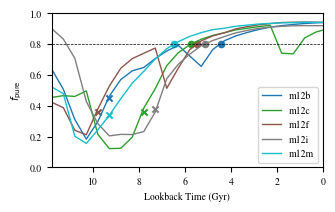

Loading existing sim_halt_dict JSON...
m12b: crossing @ 5.88 Gyr
m12b: min grad @ 9.80 Gyr

m12c: crossing @ 2.97 Gyr
m12c: min grad @ 9.80 Gyr

m12f: crossing @ 3.11 Gyr
m12f: min grad @ 7.80 Gyr

m12i: crossing @ 2.73 Gyr
m12i: min grad @ 10.30 Gyr

m12m: crossing @ 5.51 Gyr
m12m: min grad @ 8.30 Gyr



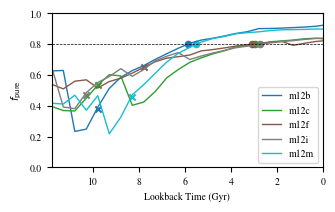

In [17]:
in_msk = True
threshold = 0.80
cont_level = 0.95

tcuts = np.arange(2, 14, 0.5)
tcuts = np.append(tcuts, timez0)

bound_form = {"in_situ": {sim: None for sim in sim_lst}, "ex_situ": {sim: None for sim in sim_lst}}
bound_onse = {"in_situ": {sim: None for sim in sim_lst}, "ex_situ": {sim: None for sim in sim_lst}}

for in_msk in [True, False]:
    if in_msk:
        sit_lab = "in_situ"
    else:
        sit_lab = "ex_situ"

    bound_path = "../data/sim_data/boundary_dict_" + str(in_msk) + ".json"

    if os.path.exists(bound_path):
        print("Loading existing sim_halt_dict JSON...")
        with open(bound_path, "r", encoding="utf-8") as f:
            dat_dict = json.load(f)

    else:
        dat_dict = {sim: None for sim in sim_lst}

        for sim in sim_lst:
            # overlap_pdf_arr = []
            # overlap_cont_arr = []
            # exclusive_surv_arr = []
            # exclusive_disr_arr = []
            frac_pure_arr = []
            times = []

            for tcut in tcuts:
                pdf_ov, cont_ov, ex_surv, ex_disr, f_pure = compute_full_diagnostics(
                    sim, tcut, in_msk, cont_level
                )

                # overlap_pdf_arr.append(pdf_ov)
                # overlap_cont_arr.append(cont_ov)
                # exclusive_surv_arr.append(ex_surv)
                # exclusive_disr_arr.append(ex_disr)
                frac_pure_arr.append(f_pure)
                # times.append(tcut)
            dat_dict[sim] = np.array(frac_pure_arr)

        dat_dict_json = to_json_serializable(dat_dict)

        # Save
        with open(bound_path, "w", encoding="utf-8") as f:
            json.dump(dat_dict_json, f, indent=4)

    x = timez0 - tcuts

    plt.figure(figsize=(3.5, 2))

    for sim in sim_lst:
        plt.plot(x, dat_dict[sim], c=sim_colors[sim], label=sim, lw=1)
        # plt.plot(x, np.gradient(dat_dict[sim], x), c=sim_colors[sim], label=sim, lw=1, ls="--")
        # plt.axvline(spin_up_lbt_dict[sim], c=sim_colors[sim], ls="--", lw=1)
    plt.xlim(timez0 - 2, 0)
    plt.ylim(0, 1)

    plt.axhline(threshold, c="k", ls="--", lw=0.5)

    crossing_times = {}
    gradient_times = {}

    for sim in sim_lst:
        y = np.asarray(dat_dict[sim], dtype=float)

        # smooth first
        y_smooth = savgol_filter(y, 5, 2)

        # derivative wrt lookback time
        dydt = np.gradient(y_smooth, x)

        # ---------------------------
        # 0.8 crossing time
        # ---------------------------
        idx = np.where((y_smooth[:-1] < threshold) & (y_smooth[1:] >= threshold))[0]

        if len(idx) > 0:
            i = idx[0]

            t_cross = np.interp(threshold, [y_smooth[i], y_smooth[i + 1]], [x[i], x[i + 1]])

            crossing_times[sim] = t_cross

            print(f"{sim}: crossing @ {t_cross:.2f} Gyr")

            # plt.axvline(t_cross, color=sim_colors[sim], lw=1, ls="--", alpha=0.8)

            # plt.scatter(t_cross, threshold, color=sim_colors[sim], s=20, zorder=10)

        # ---------------------------
        # minimum gradient time
        # ---------------------------
        i_grad = np.argmin(dydt)
        # i_grad = np.argmin(y)

        t_grad = x[i_grad]

        gradient_times[sim] = t_grad

        print(f"{sim}: min grad @ {t_grad:.2f} Gyr")
        print()

        bound_form[sit_lab][sim] = np.round(crossing_times[sim], 2)
        bound_onse[sit_lab][sim] = np.round(gradient_times[sim], 2)

        plt.scatter(t_grad, y_smooth[i_grad], marker="x", color=sim_colors[sim], s=20)
        plt.scatter(t_cross, threshold, marker="o", color=sim_colors[sim], s=20)

    plt.xlabel("Lookback Time (Gyr)")
    plt.ylabel(r"$f_{\rm pure}$")

    plt.legend()

    if in_msk:
        nam = "in_situ"
    else:
        nam = "ex_situ"

    save_loc = "../data/figures/boundaries/boundary_formation_" + nam + ".pdf"
    plt.savefig(save_loc, bbox_inches="tight")
    plt.show()

bound_form_path = "../data/sim_data/boundary_formation_lbt.json"
with open(bound_form_path, "w", encoding="utf-8") as f:
    json.dump(bound_form, f, indent=4)

bound_onse_path = "../data/sim_data/boundary_onset_lbt.json"
with open(bound_onse_path, "w", encoding="utf-8") as f:
    json.dump(bound_onse, f, indent=4)

# Plotting KDEs

In [18]:
# snap_dict = {
#     "m12b": [120, 382, 600],
#     "m12c": [120, 382, 600],
#     "m12f": [120, 382, 600],
#     "m12i": [120, 382, 600],
#     "m12m": [120, 382, 600],
# }

snap_dict = {
    "m12b": [120, 312, 600],
    "m12c": [120, 312, 600],
    "m12f": [120, 312, 600],
    "m12i": [120, 312, 600],
    "m12m": [120, 312, 600],
}

In [19]:
# pub_snaps[np.argmin(np.abs(pub_tims - 6.9))]

In [20]:
kde_path = "../data/sim_data/kde_dict.json"
if os.path.exists(kde_path):
    print("Loading existing kde_dict JSON...")
    with open(kde_path, "r", encoding="utf-8") as f:
        kde_dict = json.load(f)

else:
    kde_dict_eig = {
        sim: {"in": {snap: {} for snap in snap_dict[sim]}, "ex": {snap: {} for snap in snap_dict[sim]}}
        for sim in sim_lst
    }

    kde_dict_sma = {sim: {"in": {}, "ex": {}} for sim in sim_lst}

    for sim in sim_lst:
        # eig plots ################################################################

        for snap in snap_dict[sim]:
            tcut = pub_data[pub_data["index"] == snap]["time_Gyr"].values[0]

            iXX, iYY, iZ0_list, iZ1_list = get_kde_grids_eig(sim, tcut, True)

            iZ0a, iXXa, iYYa = average_cont(iZ0_list, iXX, iYY)
            iZ1a, iXXa, iYYa = average_cont(iZ1_list, iXX, iYY)

            kde_dict_eig[sim]["in"][snap]["XX"] = iXXa
            kde_dict_eig[sim]["in"][snap]["YY"] = iYYa
            kde_dict_eig[sim]["in"][snap]["Z0"] = iZ0a
            kde_dict_eig[sim]["in"][snap]["Z1"] = iZ1a

            eXX, eYY, eZ0_list, eZ1_list = get_kde_grids_eig(sim, tcut, False)

            eZ0a, eXXa, eYYa = average_cont(eZ0_list, eXX, eYY)
            eZ1a, eXXa, eYYa = average_cont(eZ1_list, eXX, eYY)

            kde_dict_eig[sim]["ex"][snap]["XX"] = eXXa
            kde_dict_eig[sim]["ex"][snap]["YY"] = eYYa
            kde_dict_eig[sim]["ex"][snap]["Z0"] = eZ0a
            kde_dict_eig[sim]["ex"][snap]["Z1"] = eZ1a

        # sma plots ################################################################

        fire_dir = sim_dir + sim + "/" + sim + "_res7100"
        pot_snp = agama.Potential(f"{sim_dir}{sim}/potentials/snap_{600}/combined_snap_{600}.ini")
        part = gizmo.io.Read.read_snapshots(
            ["star", "dark"], "index", 600, fire_dir, assign_hosts_rotation=True
        )

        star_pos = part["star"].prop("host.distance.principal")
        star_vel = part["star"].prop("host.velocity.principal")
        star_ic = np.hstack((star_pos, star_vel))

        dark_pos = part["dark"].prop("host.distance.principal")
        dark_vel = part["dark"].prop("host.velocity.principal")
        dark_ic = np.hstack((dark_pos, dark_vel))

        iXX, iYY, iZ0_list, iZ1_list = get_kde_grids_semi_major(sim, 600, pot_snp, star_ic, dark_ic, True)

        iZ0a, iXXa, iYYa = average_cont(iZ0_list, iXX, iYY)
        iZ1a, iXXa, iYYa = average_cont(iZ1_list, iXX, iYY)

        kde_dict_sma[sim]["in"]["XX"] = iXXa
        kde_dict_sma[sim]["in"]["YY"] = iYYa
        kde_dict_sma[sim]["in"]["Z0"] = iZ0a
        kde_dict_sma[sim]["in"]["Z1"] = iZ1a

        eXX, eYY, eZ0_list, eZ1_list = get_kde_grids_semi_major(sim, 600, pot_snp, star_ic, dark_ic, False)

        eZ0a, eXXa, eYYa = average_cont(eZ0_list, eXX, eYY)
        eZ1a, eXXa, eYYa = average_cont(eZ1_list, eXX, eYY)

        kde_dict_sma[sim]["ex"]["XX"] = eXXa
        kde_dict_sma[sim]["ex"]["YY"] = eYYa
        kde_dict_sma[sim]["ex"]["Z0"] = eZ0a
        kde_dict_sma[sim]["ex"]["Z1"] = eZ1a

    kde_dict = {"eig": kde_dict_eig, "sma": kde_dict_sma}

    kde_dict_json = to_json_serializable(kde_dict)
    with open(kde_path, "w") as f:
        json.dump(kde_dict_json, f, indent=4)

Loading existing kde_dict JSON...


In [21]:
kde_dict["eig"]["m12b"]["in"].keys()

dict_keys(['120', '382', '600', '312'])

In [22]:
# snap = 312

# for sim in sim_lst:
#     print(sim)
#     tcut = pub_data[pub_data["index"] == snap]["time_Gyr"].values[0]

#     iXX, iYY, iZ0_list, iZ1_list = get_kde_grids_eig(sim, tcut, True)

#     iZ0a, iXXa, iYYa = average_cont(iZ0_list, iXX, iYY)
#     iZ1a, iXXa, iYYa = average_cont(iZ1_list, iXX, iYY)

#     kde_dict["eig"][sim]["in"][snap] = {}

#     kde_dict["eig"][sim]["in"][snap]["XX"] = iXXa
#     kde_dict["eig"][sim]["in"][snap]["YY"] = iYYa
#     kde_dict["eig"][sim]["in"][snap]["Z0"] = iZ0a
#     kde_dict["eig"][sim]["in"][snap]["Z1"] = iZ1a

#     eXX, eYY, eZ0_list, eZ1_list = get_kde_grids_eig(sim, tcut, False)

#     eZ0a, eXXa, eYYa = average_cont(eZ0_list, eXX, eYY)
#     eZ1a, eXXa, eYYa = average_cont(eZ1_list, eXX, eYY)

#     kde_dict["eig"][sim]["ex"][snap] = {}

#     kde_dict["eig"][sim]["ex"][snap]["XX"] = eXXa
#     kde_dict["eig"][sim]["ex"][snap]["YY"] = eYYa
#     kde_dict["eig"][sim]["ex"][snap]["Z0"] = eZ0a
#     kde_dict["eig"][sim]["ex"][snap]["Z1"] = eZ1a

In [23]:
# kde_dict_json = to_json_serializable(kde_dict)
# with open(kde_path, "w") as f:
#     json.dump(kde_dict_json, f, indent=4)

In [24]:
fit_path = "../data/sim_data/boundary_fits.json"
if os.path.exists(fit_path):
    print("Loading existing sim_halt_dict JSON...")
    with open(fit_path, "r", encoding="utf-8") as f:
        fit_dict = json.load(f)

else:
    fit_dict = {sim: {"in": None, "ex": None} for sim in sim_lst}
    fit_dict["m12c_5gyr_lim"] = {"in": None}

    tcut = timez0
    for sim in sim_lst:
        fire_dir = sim_dir + sim + "/" + sim + "_res7100"
        pot_snp = agama.Potential(f"{sim_dir}{sim}/potentials/snap_{600}/combined_snap_{600}.ini")
        part = gizmo.io.Read.read_snapshots(
            ["star", "dark"], "index", 600, fire_dir, assign_hosts_rotation=True
        )

        star_pos = part["star"].prop("host.distance.principal")
        star_vel = part["star"].prop("host.velocity.principal")
        star_ic = np.hstack((star_pos, star_vel))

        dark_pos = part["dark"].prop("host.distance.principal")
        dark_vel = part["dark"].prop("host.velocity.principal")
        dark_ic = np.hstack((dark_pos, dark_vel))

        ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
        ghost_data = h5py.File(ghost_file, "r")  # open processed data file

        for in_msk in [True, False]:
            if in_msk:
                lab = "in"
            else:
                lab = "ex"
            fit_dict[sim][lab] = get_boundary(ghost_data, pot_snp, star_ic, dark_ic, tcut, in_msk, None)

        if sim == "m12c":
            fit_dict["m12c_5gyr_lim"]["in"] = get_boundary(
                ghost_data, pot_snp, star_ic, dark_ic, tcut, True, 5
            )

    fit_dict_json = to_json_serializable(fit_dict)
    with open(fit_path, "w", encoding="utf-8") as f:
        json.dump(fit_dict_json, f, indent=4)

Loading existing sim_halt_dict JSON...


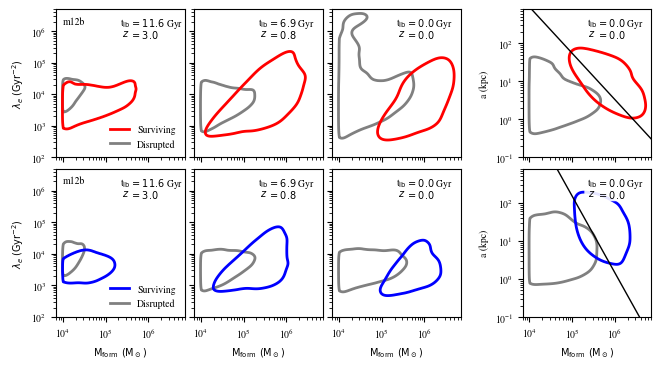

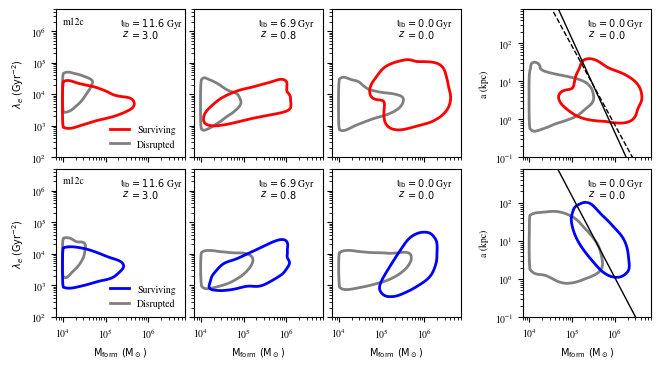

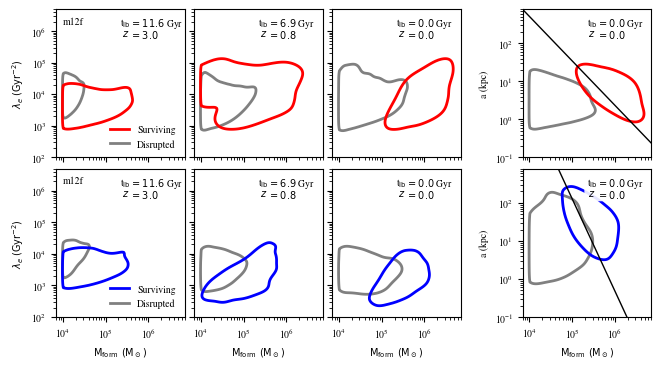

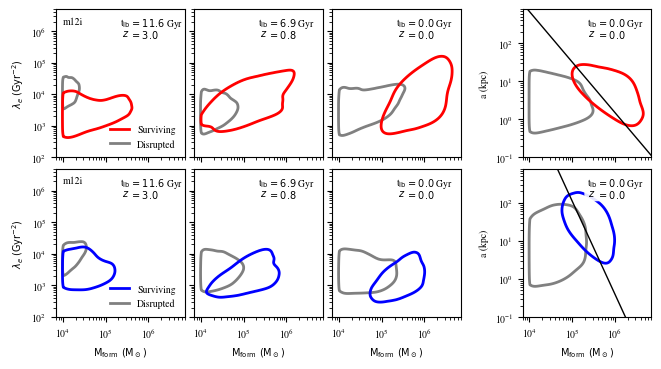

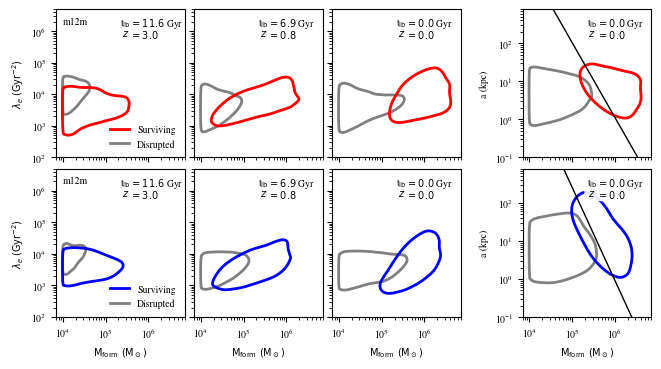

In [25]:
cont_level = 0.95
xg = np.linspace(3.5, 7, 100)

for sim in sim_lst:
    # fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(16, 6))
    fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(7.0, 4.0))
    plt.subplots_adjust(hspace=0.075, wspace=0.075)

    # Shift the last column to the right
    for ax in axs[:, 3]:
        pos = ax.get_position()
        ax.set_position(
            [
                pos.x0 + 0.075,  # shift right
                pos.y0,
                pos.width,
                pos.height,
            ]
        )

    for i, ax in enumerate(axs.flatten()):
        if i in [3, 7]:
            continue

        # plotting ##########################################

        if i < 4:
            j = i
            XXi = np.array(kde_dict["eig"][sim]["in"][str(snap_dict[sim][j])]["XX"])
            YYi = np.array(kde_dict["eig"][sim]["in"][str(snap_dict[sim][j])]["YY"])
            Z0i = np.array(kde_dict["eig"][sim]["in"][str(snap_dict[sim][j])]["Z0"])
            Z1i = np.array(kde_dict["eig"][sim]["in"][str(snap_dict[sim][j])]["Z1"])

            plot_averages(ax, Z0i, XXi, YYi, "grey", cont_level)
            plot_averages(ax, Z1i, XXi, YYi, "red", cont_level)

            tlb = pub_data[pub_data["index"] == snap_dict[sim][j]]["lookback_time_Gyr"].values[0]
            z = pub_data[pub_data["index"] == snap_dict[sim][j]]["redshift"].values[0]

            if i == 0:
                surv = Line2D([0], [0], color="red", linewidth=2, label="Surviving")
                disr = Line2D([0], [0], color="grey", linewidth=2, label="Disrupted")
                ax.legend(handles=[surv, disr], frameon=False, loc="lower right")

        else:
            j = i - 4
            XXe = np.array(kde_dict["eig"][sim]["ex"][str(snap_dict[sim][j])]["XX"])
            YYe = np.array(kde_dict["eig"][sim]["ex"][str(snap_dict[sim][j])]["YY"])
            Z0e = np.array(kde_dict["eig"][sim]["ex"][str(snap_dict[sim][j])]["Z0"])
            Z1e = np.array(kde_dict["eig"][sim]["ex"][str(snap_dict[sim][j])]["Z1"])

            plot_averages(ax, Z0e, XXe, YYe, "grey", cont_level)
            plot_averages(ax, Z1e, XXe, YYe, "blue", cont_level)

            tlb = pub_data[pub_data["index"] == snap_dict[sim][j]]["lookback_time_Gyr"].values[0]
            z = pub_data[pub_data["index"] == snap_dict[sim][j]]["redshift"].values[0]

            if j == 0:
                surv = Line2D([0], [0], color="blue", linewidth=2, label="Surviving")
                disr = Line2D([0], [0], color="grey", linewidth=2, label="Disrupted")
                ax.legend(handles=[surv, disr], frameon=False, loc="lower right")

        # add text ##########################################

        x = 0.50
        y = 0.95

        # box coordinates in axes coordinates
        box_x = x
        box_y = y - 0.15
        box_w = 0.47
        box_h = 0.13

        ax.add_patch(
            FancyBboxPatch(
                (box_x, box_y),
                box_w,
                box_h,
                transform=ax.transAxes,
                boxstyle="round,pad=0.02",
                facecolor="white",
                edgecolor="none",
                alpha=0.9,
                zorder=1,
            )
        )

        ax.text(x, y, r"t$_{\mathrm{lb}}$", transform=ax.transAxes, ha="left", va="top", zorder=2)
        ax.text(x + 0.075, y, rf"$= {tlb:.1f}$ Gyr", transform=ax.transAxes, ha="left", va="top", zorder=2)

        ax.text(x + 0.01, y - 0.08, r"$z$", transform=ax.transAxes, ha="left", va="top", zorder=2)
        ax.text(x + 0.075, y - 0.08, rf"$= {z:.1f}$", transform=ax.transAxes, ha="left", va="top", zorder=2)

        # ax.text(x, y, r"t$_{\mathrm{lb}}$", transform=ax.transAxes, ha="left", va="top")
        # ax.text(x + 0.075, y, rf"$= {tlb:.1f}$ Gyr", transform=ax.transAxes, ha="left", va="top")

        # ax.text(x + 0.01, y - 0.08, r"$z$", transform=ax.transAxes, ha="left", va="top")
        # ax.text(x + 0.075, y - 0.08, rf"$= {z:.1f}$", transform=ax.transAxes, ha="left", va="top")

        # formatting ########################################

        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.set_xlim(7 * 10**3, 7 * 10**6)
        ax.set_ylim(10**2, 5 * 10**6)

        if i < 4:
            ax.set_xticklabels([])
        else:
            ax.set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")

        if i in [0, 4]:
            ax.set_ylabel(r"$\lambda_e\;(\mathrm{Gyr}^{-2})$")
            ax.text(
                0.05,
                0.90,
                sim,
                transform=ax.transAxes,
                fontsize=7,
                bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
                ha="left",
            )
        else:
            ax.set_yticklabels([])

    for i, ax in enumerate(axs[:, 3]):
        if i == 0:
            XXi = np.array(kde_dict["sma"][sim]["in"]["XX"])
            YYi = np.array(kde_dict["sma"][sim]["in"]["YY"])
            Z0i = np.array(kde_dict["sma"][sim]["in"]["Z0"])
            Z1i = np.array(kde_dict["sma"][sim]["in"]["Z1"])

            plot_averages(ax, Z0i, XXi, YYi, "grey", cont_level)
            plot_averages(ax, Z1i, XXi, YYi, "red", cont_level)

            m = fit_dict[sim]["in"]["m"]["50"]
            c = fit_dict[sim]["in"]["c"]["50"]
            yi = m * xg + c
            ax.plot(10**xg, 10**yi, c="k", ls="-", lw=1)

            if sim == "m12c":
                m = fit_dict["m12c_5gyr_lim"]["in"]["m"]["50"]
                c = fit_dict["m12c_5gyr_lim"]["in"]["c"]["50"]
                yic = m * xg + c
                ax.plot(10**xg, 10**yic, c="k", ls="--", lw=1)

        else:
            XXe = np.array(kde_dict["sma"][sim]["ex"]["XX"])
            YYe = np.array(kde_dict["sma"][sim]["ex"]["YY"])
            Z0e = np.array(kde_dict["sma"][sim]["ex"]["Z0"])
            Z1e = np.array(kde_dict["sma"][sim]["ex"]["Z1"])

            plot_averages(ax, Z0e, XXe, YYe, "grey", cont_level)
            plot_averages(ax, Z1e, XXe, YYe, "blue", cont_level)

            m = fit_dict[sim]["ex"]["m"]["50"]
            c = fit_dict[sim]["ex"]["c"]["50"]
            ye = m * xg + c
            ax.plot(10**xg, 10**ye, c="k", ls="-", lw=1)

        tlb = pub_data[pub_data["index"] == 600]["lookback_time_Gyr"].values[0]
        z = pub_data[pub_data["index"] == 600]["redshift"].values[0]

        ax.add_patch(
            FancyBboxPatch(
                (box_x, box_y),
                box_w,
                box_h,
                transform=ax.transAxes,
                boxstyle="round,pad=0.02",
                facecolor="white",
                edgecolor="none",
                alpha=0.9,
                zorder=1,
            )
        )

        ax.text(x, y, r"t$_{\mathrm{lb}}$", transform=ax.transAxes, ha="left", va="top")
        ax.text(x + 0.075, y, rf"$= {tlb:.1f}$ Gyr", transform=ax.transAxes, ha="left", va="top")

        ax.text(x + 0.01, y - 0.08, r"$z$", transform=ax.transAxes, ha="left", va="top")
        ax.text(x + 0.075, y - 0.08, rf"$= {z:.1f}$", transform=ax.transAxes, ha="left", va="top")

        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.set_xlim(7 * 10**3, 7 * 10**6)
        ax.set_ylim(10**-1, 8 * 10**2)

        if i == 0:
            ax.set_xticklabels([])
        else:
            ax.set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")

        ax.set_ylabel(r"a (kpc)")

    conts = "../data/figures/boundaries/" + sim + "_kde_boundaries.pdf"
    fig.savefig(conts)

    plt.show()

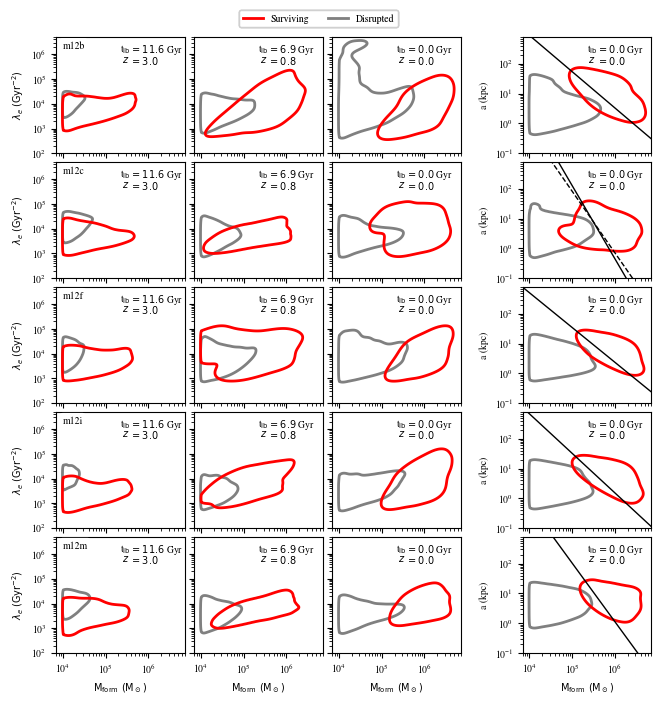

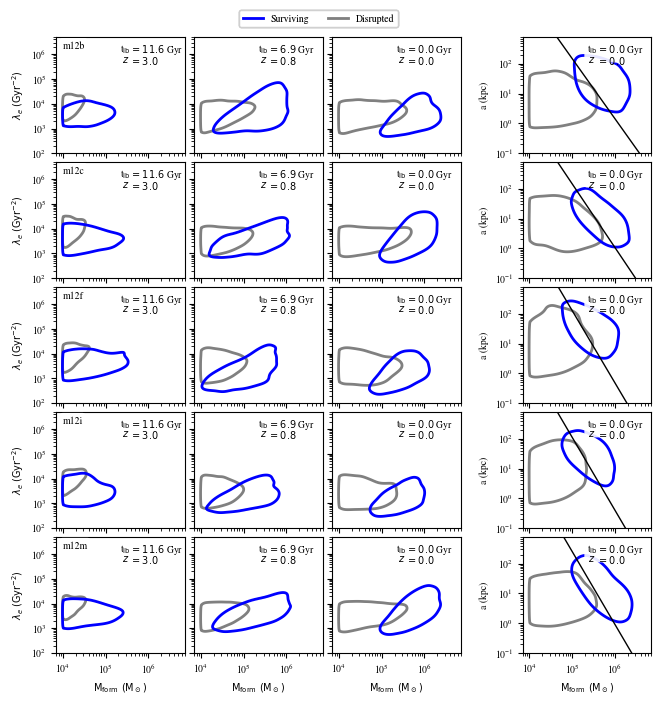

In [26]:
cont_level = 0.95

for in_msk in [True, False]:
    if in_msk:
        col = "red"
        in_lab = "in"
        sav_lab = "in_situ"
    else:
        col = "blue"
        in_lab = "ex"
        sav_lab = "ex_situ"

    fig, axs = plt.subplots(nrows=5, ncols=4, figsize=(7, 8))
    plt.subplots_adjust(hspace=0.075, wspace=0.075)

    # Shift the last column to the right
    for ax in axs[:, 3]:
        pos = ax.get_position()
        ax.set_position(
            [
                pos.x0 + 0.075,  # shift right
                pos.y0,
                pos.width,
                pos.height,
            ]
        )

    for i, sim in enumerate(sim_lst):
        for j in [0, 1, 2]:
            ax = axs[i, j]

            XX = np.array(kde_dict["eig"][sim][in_lab][str(snap_dict[sim][j])]["XX"])
            YY = np.array(kde_dict["eig"][sim][in_lab][str(snap_dict[sim][j])]["YY"])
            Z0 = np.array(kde_dict["eig"][sim][in_lab][str(snap_dict[sim][j])]["Z0"])
            Z1 = np.array(kde_dict["eig"][sim][in_lab][str(snap_dict[sim][j])]["Z1"])

            plot_averages(ax, Z0, XX, YY, "grey", cont_level)
            plot_averages(ax, Z1, XX, YY, col, cont_level)

            tlb = pub_data[pub_data["index"] == snap_dict[sim][j]]["lookback_time_Gyr"].values[0]
            z = pub_data[pub_data["index"] == snap_dict[sim][j]]["redshift"].values[0]

            ax.set_xscale("log")
            ax.set_yscale("log")

            ax.set_xlim(7 * 10**3, 7 * 10**6)
            ax.set_ylim(10**2, 5 * 10**6)

            # add text ##########################################

            # x = 0.68
            # y = 0.95

            x = 0.50
            y = 0.95

            # box coordinates in axes coordinates
            box_x = x
            box_y = y - 0.15
            box_w = 0.47
            box_h = 0.13

            ax.add_patch(
                FancyBboxPatch(
                    (box_x, box_y),
                    box_w,
                    box_h,
                    transform=ax.transAxes,
                    boxstyle="round,pad=0.02",
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.9,
                    zorder=1,
                )
            )

            ax.text(x, y, r"t$_{\mathrm{lb}}$", transform=ax.transAxes, ha="left", va="top")
            ax.text(x + 0.075, y, rf"$= {tlb:.1f}$ Gyr", transform=ax.transAxes, ha="left", va="top")

            ax.text(x + 0.01, y - 0.10, r"$z$", transform=ax.transAxes, ha="left", va="top")
            ax.text(x + 0.075, y - 0.10, rf"$= {z:.1f}$", transform=ax.transAxes, ha="left", va="top")

            # formatting ########################################

            ax.set_xscale("log")
            ax.set_yscale("log")

            ax.set_xlim(7 * 10**3, 7 * 10**6)
            ax.set_ylim(10**2, 5 * 10**6)

            if j == 0:
                ax.set_ylabel(r"$\lambda_e\;(\mathrm{Gyr}^{-2})$")
                ax.text(
                    0.05,
                    0.90,
                    sim,
                    fontsize=7,
                    transform=ax.transAxes,
                    bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
                    ha="left",
                )
            else:
                ax.set_yticklabels([])

            if j == 0:
                surv = Line2D([0], [0], color=col, linewidth=2, label="Surviving")
                disr = Line2D([0], [0], color="grey", linewidth=2, label="Disrupted")
                # ax.legend(handles=[surv, disr], frameon=False, loc="lower right", ncols=2)

                fig.legend(
                    handles=[surv, disr],
                    loc="upper center",
                    bbox_to_anchor=(0.5, 0.92),
                    ncol=2,
                    frameon=True,
                )

        j = 3
        ax = axs[i, j]

        XX = np.array(kde_dict["sma"][sim][in_lab]["XX"])
        YY = np.array(kde_dict["sma"][sim][in_lab]["YY"])
        Z0 = np.array(kde_dict["sma"][sim][in_lab]["Z0"])
        Z1 = np.array(kde_dict["sma"][sim][in_lab]["Z1"])

        plot_averages(ax, Z0, XX, YY, "grey", cont_level)
        plot_averages(ax, Z1, XX, YY, col, cont_level)

        m = fit_dict[sim][in_lab]["m"]["50"]
        c = fit_dict[sim][in_lab]["c"]["50"]
        yi = m * xg + c
        ax.plot(10**xg, 10**yi, c="k", ls="-", lw=1)

        if (in_msk) & (sim == "m12c"):
            m = fit_dict["m12c_5gyr_lim"]["in"]["m"]["50"]
            c = fit_dict["m12c_5gyr_lim"]["in"]["c"]["50"]
            yic = m * xg + c
            ax.plot(10**xg, 10**yic, c="k", ls="--", lw=1)

        tlb = pub_data[pub_data["index"] == 600]["lookback_time_Gyr"].values[0]
        z = pub_data[pub_data["index"] == 600]["redshift"].values[0]

        ax.set_ylabel(r"a (kpc)")

        ax.add_patch(
            FancyBboxPatch(
                (box_x, box_y),
                box_w,
                box_h,
                transform=ax.transAxes,
                boxstyle="round,pad=0.02",
                facecolor="white",
                edgecolor="none",
                alpha=0.9,
                zorder=1,
            )
        )

        ax.text(x, y, r"t$_{\mathrm{lb}}$", transform=ax.transAxes, ha="left", va="top")
        ax.text(x + 0.075, y, rf"$= {tlb:.1f}$ Gyr", transform=ax.transAxes, ha="left", va="top")

        ax.text(x + 0.01, y - 0.10, r"$z$", transform=ax.transAxes, ha="left", va="top")
        ax.text(x + 0.075, y - 0.10, rf"$= {z:.1f}$", transform=ax.transAxes, ha="left", va="top")

        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.set_xlim(7 * 10**3, 7 * 10**6)
        ax.set_ylim(10**-1, 8 * 10**2)

        for j in [0, 1, 2, 3]:
            if i != 4:
                axs[i, j].set_xticklabels([])
            else:
                axs[i, j].set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")

    conts = "../data/figures/boundaries/" + "kde_boundaries_" + sav_lab + ".pdf"
    fig.savefig(conts)

    plt.show()

# Boundary Fits Updated

In [27]:
def lower_bound(x, m, b):
    return m * x + b


def kde_threshold(Z, fraction):
    """Return KDE level that encloses fraction of total probability."""
    sorted_Z = np.sort(Z.ravel())[::-1]  # descending
    cumsum = np.cumsum(sorted_Z)
    cumsum /= cumsum[-1]  # normalize
    # Find the smallest Z value where cumulative sum >= fraction
    level = sorted_Z[np.searchsorted(cumsum, fraction)]
    return level


def get_lower_bound(
    x,
    y,
    xlims=(3.0, 8.0),
    ylims=(-1.0, 3.0),
    ngrid=500,
    cont_lvl=0.98,
):

    xlog = np.log10(x)
    ylog = np.log10(y)
    xylog = np.vstack([xlog, ylog])

    xmin, xmax = xlims
    ymin, ymax = ylims

    X, Y = np.meshgrid(
        np.linspace(xmin, xmax, ngrid),
        np.linspace(ymin, ymax, ngrid),
    )

    kde = gaussian_kde(xylog)
    Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)

    lvl = kde_threshold(Z, cont_lvl)

    cont = plt.contour(X, Y, Z, levels=[lvl])
    plt.close()

    contp = cont.get_paths()[0]
    vert = contp.vertices

    xcon = vert[:, 0]
    ycon = vert[:, 1]

    xbins = np.linspace(xcon.min(), xcon.max(), 100)
    xbins_cen = 0.5 * (xbins[:-1] + xbins[1:])

    x_lower = []
    y_lower = []

    for i in range(len(xbins) - 1):
        mask = (xcon >= xbins[i]) & (xcon < xbins[i + 1])

        if np.any(mask):
            x_lower.append(xbins_cen[i])
            y_lower.append(np.min(ycon[mask]))

    x_lower = np.asarray(x_lower)
    y_lower = np.asarray(y_lower)

    p0 = [-1.0, 1.0]
    params, cov = curve_fit(lower_bound, x_lower, y_lower, p0=p0)

    best_fit_dict = {
        "m": params[0],
        "b": params[1],
        "cov": cov,
    }

    xfit = np.logspace(xmin, xmax)
    xfitlog = np.log10(xfit)

    yfitlog = lower_bound(xfitlog, *params)
    yfit = 10**yfitlog

    return xfit, yfit, best_fit_dict


def get_boundary_update(ghost_data, pot_snp, star_ic, dark_ic, tcut, in_msk, age_cut):

    fit_results = []
    fit_covs = []

    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]

        if in_msk:
            acc = src_dat["grpid"][()] == 0
        else:
            acc = src_dat["grpid"][()] != 0

        mfor = 10 ** src_dat["logm_tfor"][()]
        smaj = get_semi_major(src_dat, pot_snp, star_ic, dark_ic)

        sa_msk = src_dat["sa_flag"][()] != 0

        tacc = np.asarray(src_dat["tacc"][()])
        tdis = np.asarray(src_dat["tdis"][()]).copy()
        tfor = np.asarray(src_dat["tfor"][()])

        if age_cut is not None:
            tage = tcut - tfor
            tage_msk = tage > age_cut
        else:
            tage_msk = np.ones(len(tfor), dtype=bool)

        tdis[tdis == -1] = np.inf

        tfor_msk = tfor <= tcut
        tdis_msk = tdis <= tcut
        tacc_msk = tacc <= tcut

        mask_common = tfor_msk & tacc_msk & acc & sa_msk & tage_msk

        x1 = mfor[mask_common & (~tdis_msk)]
        y1 = smaj[mask_common & (~tdis_msk)]

        valid1 = (x1 > 0) & (y1 > 0)

        x1 = x1[valid1]
        y1 = y1[valid1]

        _, _, fit_dict = get_lower_bound(x1, y1)

        fit_results.append([fit_dict["m"], fit_dict["b"]])

        fit_covs.append(fit_dict["cov"])

    fit_results = np.asarray(fit_results)
    fit_covs = np.asarray(fit_covs)

    N = len(fit_results)

    mean_fit = {"m": np.mean(fit_results[:, 0]), "b": np.mean(fit_results[:, 1])}

    err_fit = {}

    for i, name in enumerate(["m", "b"]):
        # contribution from curve_fit covariance
        fit_var = np.sum(fit_covs[:, i, i]) / N**2

        # realization-to-realization scatter
        stat_var = np.var(fit_results[:, i], ddof=1) / N

        err_fit[name] = np.sqrt(fit_var + stat_var)

    # full covariance of the mean fit
    mean_cov = np.sum(fit_covs, axis=0) / N**2
    mean_cov += np.cov(fit_results.T, ddof=1) / N

    return mean_fit, err_fit


In [28]:
def get_future_boundary(ghost_data, pot_snp, star_ic, dark_ic, tcut, dt_future, in_msk, age_cut=None):

    fit_results = []
    fit_covs = []

    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]

        if in_msk:
            acc = src_dat["grpid"][()] == 0
        else:
            acc = src_dat["grpid"][()] != 0

        mfor = 10 ** src_dat["logm_tfor"][()]
        smaj = get_semi_major(src_dat, pot_snp, star_ic, dark_ic)
        sa_msk = src_dat["sa_flag"][()] != 0

        tacc = np.array(src_dat["tacc"][()])
        tdis = np.array(src_dat["tdis"][()]).copy()
        tfor = np.array(src_dat["tfor"][()])

        # will they survive x time in the future?
        t600 = pub_tims[pub_snaps == 600][0]
        t534 = pub_tims[pub_snaps == 534][0]
        tdif = t600 - t534

        snp_600 = ghost_data[it_id]["snapshots"]["snap600"]
        snp_534 = ghost_data[it_id]["snapshots"]["snap534"]

        gcid_600 = snp_600["gcid"][()]
        gcid_534 = snp_534["gcid"][()]

        mass_600 = 10 ** snp_600["logm"][()]
        mass_534 = 10 ** snp_534["logm"][()]

        # Match snapshots
        gcid_to_idx534 = {g: i for i, g in enumerate(gcid_534)}

        tleft_dict = {}

        for i600, gcid in enumerate(gcid_600):
            if gcid in gcid_to_idx534:
                i534 = gcid_to_idx534[gcid]

                mdif = mass_534[i534] - mass_600[i600]
                ml_rate = mdif / tdif

                # if no detected mass loss in the time default to inf
                if ml_rate <= 0:
                    tleft = np.inf
                    print("1 more")
                else:
                    tleft = mass_600[i600] / ml_rate
                tleft_dict[gcid] = tleft

        # Source catalogue
        src_dat = ghost_data[it_id]["source"]
        gcid_src = src_dat["gcid"][()]

        # survive in the future?
        sf_msk = np.zeros(len(gcid_src), dtype=bool)
        for i, gcid in enumerate(gcid_src):
            if gcid in tleft_dict:
                sf_msk[i] = tleft_dict[gcid] > dt_future

        ############################################################

        if age_cut is not None:
            tage = tcut - tfor
            tage_msk = tage > age_cut
        else:
            tage_msk = np.ones(len(tfor), dtype=bool)

        tdis[tdis == -1] = np.inf

        tfor_msk = tfor <= tcut
        # tdis_msk = tdis <= tcut
        tacc_msk = tacc <= tcut

        mask_common = tfor_msk & tacc_msk & acc & sa_msk & tage_msk

        x_surv = mfor[mask_common & sf_msk]
        y_surv = smaj[mask_common & sf_msk]

        valid = (x_surv > 0) & (y_surv > 0)

        x_surv, y_surv = x_surv[valid], y_surv[valid]

        # Need enough points for KDE
        if len(x_surv) < 5:
            continue
        else:
            _, _, fit_dict = get_lower_bound(x_surv, y_surv)

            fit_results.append([fit_dict["m"], fit_dict["b"]])
            fit_covs.append(fit_dict["cov"])

    fit_results = np.asarray(fit_results)
    fit_covs = np.asarray(fit_covs)

    N = len(fit_results)
    mean_fit = {"m": np.mean(fit_results[:, 0]), "b": np.mean(fit_results[:, 1])}

    err_fit = {}

    for i, name in enumerate(["m", "b"]):
        # contribution from curve_fit covariance
        fit_var = np.sum(fit_covs[:, i, i]) / N**2

        # realization-to-realization scatter
        stat_var = np.var(fit_results[:, i], ddof=1) / N

        err_fit[name] = np.sqrt(fit_var + stat_var)

        # full covariance of the mean fit
        mean_cov = np.sum(fit_covs, axis=0) / N**2
        mean_cov += np.cov(fit_results.T, ddof=1) / N

    return mean_fit, err_fit

In [29]:
fit_upd_path = "../data/sim_data/boundary_fits_updated.json"
if os.path.exists(fit_upd_path):
    print("Loading existing sim_halt_dict JSON...")
    with open(fit_upd_path, "r", encoding="utf-8") as f:
        fit_upd_dict = json.load(f)

else:
    fit_upd_dict = {sim: {"in": None, "ex": None} for sim in sim_lst}
    fit_upd_dict["m12c_5gyr_lim"] = {"in": None}

    tcut = timez0
    for sim in sim_lst:
        fire_dir = sim_dir + sim + "/" + sim + "_res7100"
        pot_snp = agama.Potential(f"{sim_dir}{sim}/potentials/snap_{600}/combined_snap_{600}.ini")
        part = gizmo.io.Read.read_snapshots(
            ["star", "dark"], "index", 600, fire_dir, assign_hosts_rotation=True
        )

        star_pos = part["star"].prop("host.distance.principal")
        star_vel = part["star"].prop("host.velocity.principal")
        star_ic = np.hstack((star_pos, star_vel))

        dark_pos = part["dark"].prop("host.distance.principal")
        dark_vel = part["dark"].prop("host.velocity.principal")
        dark_ic = np.hstack((dark_pos, dark_vel))

        ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
        ghost_data = h5py.File(ghost_file, "r")  # open processed data file

        for in_msk in [True, False]:
            if in_msk:
                lab = "in"
            else:
                lab = "ex"

            mean_fit, err_fit = get_boundary_update(ghost_data, pot_snp, star_ic, dark_ic, tcut, in_msk, None)
            fit_dict = {"avg": mean_fit, "std": err_fit}
            fit_upd_dict[sim][lab] = fit_dict

            # fit_upd_dict[sim][lab] = get_boundary_update(
            #     ghost_data, pot_snp, star_ic, dark_ic, tcut, in_msk, None
            # )

        if sim == "m12c":
            mean_fit, err_fit = get_boundary_update(ghost_data, pot_snp, star_ic, dark_ic, tcut, in_msk, None)
            fit_dict = {"avg": mean_fit, "std": err_fit}
            fit_upd_dict["m12c_5gyr_lim"]["in"] = fit_dict

            # fit_upd_dict["m12c_5gyr_lim"]["in"] = get_boundary_update(
            #     ghost_data, pot_snp, star_ic, dark_ic, tcut, True, 5
            # )

    fit_upd_dict_json = to_json_serializable(fit_upd_dict)
    with open(fit_upd_path, "w", encoding="utf-8") as f:
        json.dump(fit_upd_dict_json, f, indent=4)

Loading existing sim_halt_dict JSON...


## future boundary

In [30]:
fit_fut_path = "../data/sim_data/boundary_fits_future.json"
if os.path.exists(fit_fut_path):
    print("Loading existing sim_halt_dict JSON...")
    with open(fit_fut_path, "r", encoding="utf-8") as f:
        fit_fut_dict = json.load(f)

else:
    fit_fut_dict = {sim: {"in": None, "ex": None} for sim in sim_lst}

    tcut = timez0
    # dt_future = timez0

    for sim in sim_lst:
        fire_dir = sim_dir + sim + "/" + sim + "_res7100"
        pot_snp = agama.Potential(f"{sim_dir}{sim}/potentials/snap_{600}/combined_snap_{600}.ini")
        part = gizmo.io.Read.read_snapshots(
            ["star", "dark"], "index", 600, fire_dir, assign_hosts_rotation=True
        )

        dt_future = ut.constant.hubble_time / part.info["hubble"]

        star_pos = part["star"].prop("host.distance.principal")
        star_vel = part["star"].prop("host.velocity.principal")
        star_ic = np.hstack((star_pos, star_vel))

        dark_pos = part["dark"].prop("host.distance.principal")
        dark_vel = part["dark"].prop("host.velocity.principal")
        dark_ic = np.hstack((dark_pos, dark_vel))

        ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
        ghost_data = h5py.File(ghost_file, "r")  # open processed data file

        for in_msk in [True, False]:
            if in_msk:
                lab = "in"
            else:
                lab = "ex"

            mean_fit, err_fit = get_future_boundary(
                ghost_data, pot_snp, star_ic, dark_ic, tcut, dt_future, in_msk, age_cut=None
            )
            fit_dict = {"avg": mean_fit, "std": err_fit}
            fit_fut_dict[sim][lab] = fit_dict

    fit_fut_dict_json = to_json_serializable(fit_fut_dict)
    with open(fit_fut_path, "w", encoding="utf-8") as f:
        json.dump(fit_fut_dict_json, f, indent=4)

Loading existing sim_halt_dict JSON...


# Updated Boundary

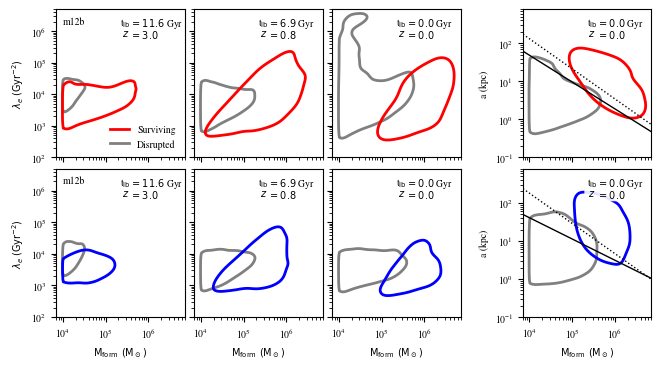

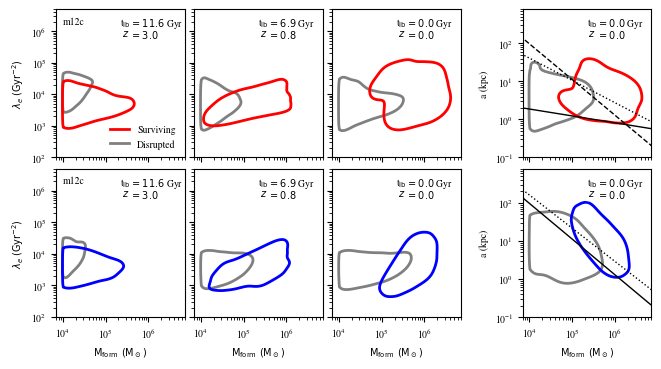

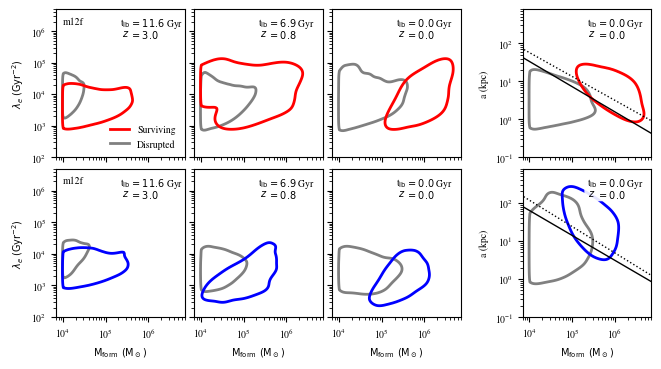

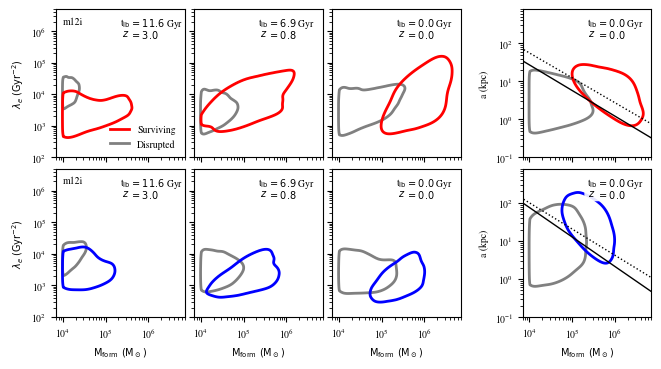

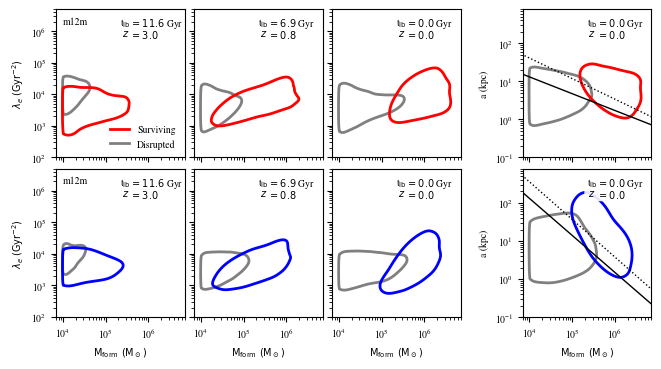

In [58]:
cont_level = 0.95
xg = np.linspace(3.5, 7, 100)

for sim in sim_lst:
    fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(7.0, 4.0))
    plt.subplots_adjust(hspace=0.075, wspace=0.075)

    # Shift the last column to the right
    for ax in axs[:, 3]:
        pos = ax.get_position()
        ax.set_position(
            [
                pos.x0 + 0.075,  # shift right
                pos.y0,
                pos.width,
                pos.height,
            ]
        )

    for i, ax in enumerate(axs.flatten()):
        if i in [3, 7]:
            continue

        # plotting ##########################################

        if i < 4:
            j = i
            XXi = np.array(kde_dict["eig"][sim]["in"][str(snap_dict[sim][j])]["XX"])
            YYi = np.array(kde_dict["eig"][sim]["in"][str(snap_dict[sim][j])]["YY"])
            Z0i = np.array(kde_dict["eig"][sim]["in"][str(snap_dict[sim][j])]["Z0"])
            Z1i = np.array(kde_dict["eig"][sim]["in"][str(snap_dict[sim][j])]["Z1"])

            plot_averages(ax, Z0i, XXi, YYi, "grey", cont_level)
            plot_averages(ax, Z1i, XXi, YYi, "red", cont_level)

            tlb = pub_data[pub_data["index"] == snap_dict[sim][j]]["lookback_time_Gyr"].values[0]
            z = pub_data[pub_data["index"] == snap_dict[sim][j]]["redshift"].values[0]

            if i == 0:
                surv = Line2D([0], [0], color="red", linewidth=2, label="Surviving")
                disr = Line2D([0], [0], color="grey", linewidth=2, label="Disrupted")
                ax.legend(handles=[surv, disr], frameon=False, loc="lower right")

        else:
            j = i - 4
            XXe = np.array(kde_dict["eig"][sim]["ex"][str(snap_dict[sim][j])]["XX"])
            YYe = np.array(kde_dict["eig"][sim]["ex"][str(snap_dict[sim][j])]["YY"])
            Z0e = np.array(kde_dict["eig"][sim]["ex"][str(snap_dict[sim][j])]["Z0"])
            Z1e = np.array(kde_dict["eig"][sim]["ex"][str(snap_dict[sim][j])]["Z1"])

            plot_averages(ax, Z0e, XXe, YYe, "grey", cont_level)
            plot_averages(ax, Z1e, XXe, YYe, "blue", cont_level)

            tlb = pub_data[pub_data["index"] == snap_dict[sim][j]]["lookback_time_Gyr"].values[0]
            z = pub_data[pub_data["index"] == snap_dict[sim][j]]["redshift"].values[0]

            if j == 0:
                surv = Line2D([0], [0], color="blue", linewidth=2, label="Surviving")
                disr = Line2D([0], [0], color="grey", linewidth=2, label="Disrupted")
                # ax.legend(handles=[surv, disr], frameon=False, loc="lower right")

        # add text ##########################################

        x = 0.50
        y = 0.95

        # box coordinates in axes coordinates
        box_x = x
        box_y = y - 0.15
        box_w = 0.47
        box_h = 0.13

        ax.add_patch(
            FancyBboxPatch(
                (box_x, box_y),
                box_w,
                box_h,
                transform=ax.transAxes,
                boxstyle="round,pad=0.02",
                facecolor="white",
                edgecolor="none",
                alpha=0.9,
                zorder=1,
            )
        )

        ax.text(x, y, r"t$_{\mathrm{lb}}$", transform=ax.transAxes, ha="left", va="top")
        ax.text(x + 0.075, y, rf"$= {tlb:.1f}$ Gyr", transform=ax.transAxes, ha="left", va="top")

        ax.text(x + 0.01, y - 0.08, r"$z$", transform=ax.transAxes, ha="left", va="top")
        ax.text(x + 0.075, y - 0.08, rf"$= {z:.1f}$", transform=ax.transAxes, ha="left", va="top")

        # formatting ########################################

        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.set_xlim(7 * 10**3, 7 * 10**6)
        ax.set_ylim(10**2, 5 * 10**6)

        if i < 4:
            ax.set_xticklabels([])
        else:
            ax.set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")

        if i in [0, 4]:
            ax.set_ylabel(r"$\lambda_e\;(\mathrm{Gyr}^{-2})$")
            ax.text(
                0.05,
                0.90,
                sim,
                transform=ax.transAxes,
                fontsize=7,
                bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
                ha="left",
            )
        else:
            ax.set_yticklabels([])

    for i, ax in enumerate(axs[:, 3]):
        if i == 0:
            XXi = np.array(kde_dict["sma"][sim]["in"]["XX"])
            YYi = np.array(kde_dict["sma"][sim]["in"]["YY"])
            Z0i = np.array(kde_dict["sma"][sim]["in"]["Z0"])
            Z1i = np.array(kde_dict["sma"][sim]["in"]["Z1"])

            plot_averages(ax, Z0i, XXi, YYi, "grey", cont_level)
            plot_averages(ax, Z1i, XXi, YYi, "red", cont_level)

            params = (fit_upd_dict[sim]["in"]["avg"]["m"], fit_upd_dict[sim]["in"]["avg"]["b"])
            params_fut = (fit_fut_dict[sim]["in"]["avg"]["m"], fit_fut_dict[sim]["in"]["avg"]["b"])

            yg = lower_bound(xg, *params)
            ax.plot(10**xg, 10**yg, c="k", lw=1)

            yf = lower_bound(xg, *params_fut)
            ax.plot(10**xg, 10**yf, c="k", lw=1, ls=":")

            if sim == "m12c":
                params = (
                    fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["m"],
                    fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["b"],
                )

                yic = lower_bound(xg, *params)
                ax.plot(10**xg, 10**yic, c="k", ls="--", lw=1)

        else:
            XXe = np.array(kde_dict["sma"][sim]["ex"]["XX"])
            YYe = np.array(kde_dict["sma"][sim]["ex"]["YY"])
            Z0e = np.array(kde_dict["sma"][sim]["ex"]["Z0"])
            Z1e = np.array(kde_dict["sma"][sim]["ex"]["Z1"])

            plot_averages(ax, Z0e, XXe, YYe, "grey", cont_level)
            plot_averages(ax, Z1e, XXe, YYe, "blue", cont_level)

            params = (fit_upd_dict[sim]["ex"]["avg"]["m"], fit_upd_dict[sim]["ex"]["avg"]["b"])
            params_fut = (fit_fut_dict[sim]["ex"]["avg"]["m"], fit_fut_dict[sim]["ex"]["avg"]["b"])

            yg = lower_bound(xg, *params)
            ax.plot(10**xg, 10**yg, c="k", ls="-", lw=1)

            yf = lower_bound(xg, *params_fut)
            ax.plot(10**xg, 10**yf, c="k", lw=1, ls=":")

        tlb = pub_data[pub_data["index"] == 600]["lookback_time_Gyr"].values[0]
        z = pub_data[pub_data["index"] == 600]["redshift"].values[0]

        ax.add_patch(
            FancyBboxPatch(
                (box_x, box_y),
                box_w,
                box_h,
                transform=ax.transAxes,
                boxstyle="round,pad=0.02",
                facecolor="white",
                edgecolor="none",
                alpha=0.9,
                zorder=1,
            )
        )

        ax.text(x, y, r"t$_{\mathrm{lb}}$", transform=ax.transAxes, ha="left", va="top")
        ax.text(x + 0.075, y, rf"$= {tlb:.1f}$ Gyr", transform=ax.transAxes, ha="left", va="top")

        ax.text(x + 0.01, y - 0.08, r"$z$", transform=ax.transAxes, ha="left", va="top")
        ax.text(x + 0.075, y - 0.08, rf"$= {z:.1f}$", transform=ax.transAxes, ha="left", va="top")

        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.set_xlim(7 * 10**3, 7 * 10**6)
        ax.set_ylim(10**-1, 8 * 10**2)

        if i == 0:
            ax.set_xticklabels([])
        else:
            ax.set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")

        ax.set_ylabel(r"a (kpc)")

    conts = "../data/figures/boundaries/" + sim + "_kde_boundaries_updated.pdf"
    fig.savefig(conts)

    plt.show()

m12b in m: -0.71 +/- 0.01  b: 4.51 +/- 0.07
Future m12b in m: -0.79 +/- 0.02  b: 5.29 +/- 0.13

m12c in m: -0.18 +/- 0.01  b: 1.0 +/- 0.08
Future m12c in m: -0.59 +/- 0.02  b: 3.96 +/- 0.14
m12c_5gyr_lim in m: -0.94 +/- 0.02  b: 5.75 +/- 0.13

m12f in m: -0.66 +/- 0.01  b: 4.18 +/- 0.06
Future m12f in m: -0.63 +/- 0.02  b: 4.27 +/- 0.12

m12i in m: -0.67 +/- 0.01  b: 4.13 +/- 0.06
Future m12i in m: -0.65 +/- 0.02  b: 4.37 +/- 0.12

m12m in m: -0.44 +/- 0.01  b: 2.89 +/- 0.08
Future m12m in m: -0.54 +/- 0.02  b: 3.78 +/- 0.12



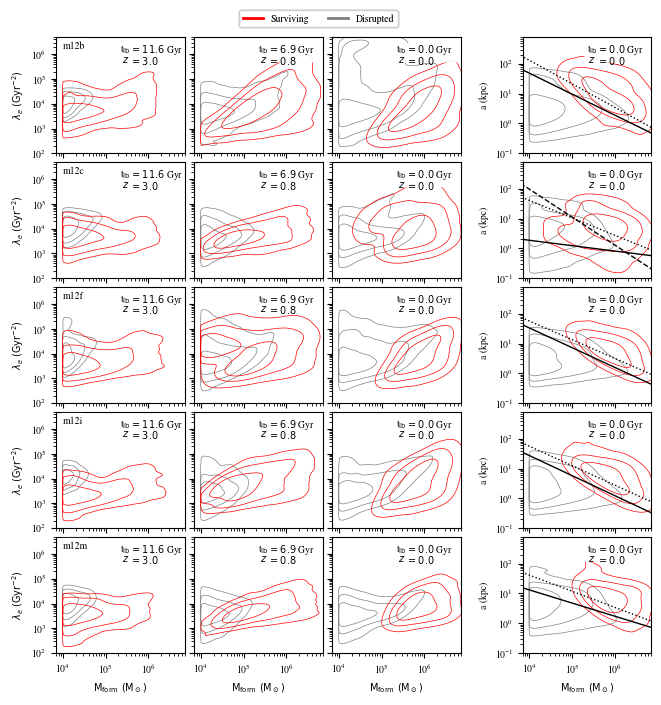

m12b ex m: -0.56 +/- 0.03  b: 3.85 +/- 0.15
Future m12b ex m: -0.8 +/- 0.03  b: 5.44 +/- 0.18

m12c ex m: -0.94 +/- 0.02  b: 5.75 +/- 0.13
Future m12c ex m: -0.87 +/- 0.04  b: 5.71 +/- 0.25

m12f ex m: -0.66 +/- 0.03  b: 4.43 +/- 0.16
Future m12f ex m: -0.69 +/- 0.03  b: 4.85 +/- 0.18

m12i ex m: -0.78 +/- 0.03  b: 4.99 +/- 0.13
Future m12i ex m: -0.69 +/- 0.04  b: 4.77 +/- 0.19

m12m ex m: -0.98 +/- 0.02  b: 6.02 +/- 0.13
Future m12m ex m: -0.99 +/- 0.03  b: 6.52 +/- 0.2



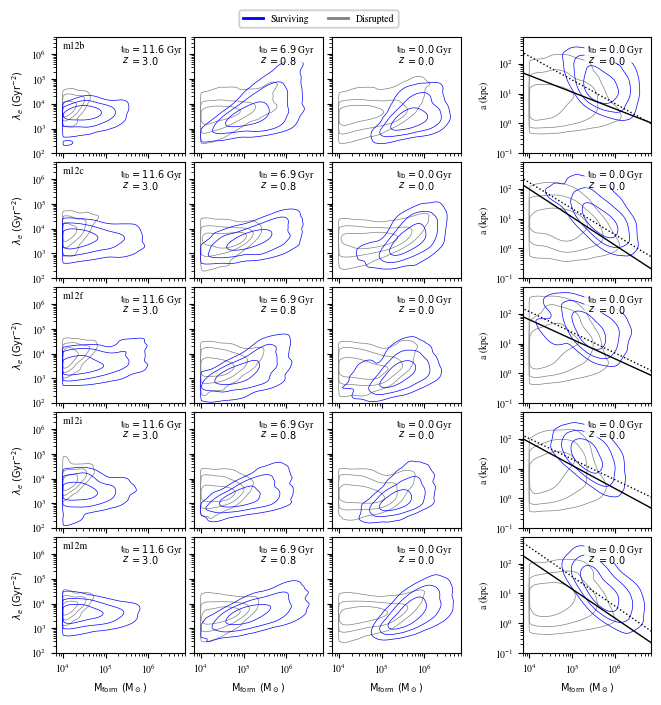

In [64]:
cont_level = [0.6827, 0.9545, 0.9973]
lw = 0.5

for in_msk in [True, False]:
    if in_msk:
        col = "red"
        in_lab = "in"
        sav_lab = "in_situ"
    else:
        col = "blue"
        in_lab = "ex"
        sav_lab = "ex_situ"

    fig, axs = plt.subplots(nrows=5, ncols=4, figsize=(7, 8))
    plt.subplots_adjust(hspace=0.075, wspace=0.075)

    # Shift the last column to the right
    for ax in axs[:, 3]:
        pos = ax.get_position()
        ax.set_position(
            [
                pos.x0 + 0.075,  # shift right
                pos.y0,
                pos.width,
                pos.height,
            ]
        )

    for i, sim in enumerate(sim_lst):
        for j in [0, 1, 2]:
            ax = axs[i, j]

            XX = np.array(kde_dict["eig"][sim][in_lab][str(snap_dict[sim][j])]["XX"])
            YY = np.array(kde_dict["eig"][sim][in_lab][str(snap_dict[sim][j])]["YY"])
            Z0 = np.array(kde_dict["eig"][sim][in_lab][str(snap_dict[sim][j])]["Z0"])
            Z1 = np.array(kde_dict["eig"][sim][in_lab][str(snap_dict[sim][j])]["Z1"])

            plot_averages(ax, Z0, XX, YY, "grey", cont_level, lw)
            plot_averages(ax, Z1, XX, YY, col, cont_level, lw)

            tlb = pub_data[pub_data["index"] == snap_dict[sim][j]]["lookback_time_Gyr"].values[0]
            z = pub_data[pub_data["index"] == snap_dict[sim][j]]["redshift"].values[0]

            ax.set_xscale("log")
            ax.set_yscale("log")

            ax.set_xlim(7 * 10**3, 7 * 10**6)
            ax.set_ylim(10**2, 5 * 10**6)

            # add text ##########################################

            x = 0.50
            y = 0.95

            # box coordinates in axes coordinates
            box_x = x
            box_y = y - 0.15
            box_w = 0.47
            box_h = 0.13

            ax.add_patch(
                FancyBboxPatch(
                    (box_x, box_y),
                    box_w,
                    box_h,
                    transform=ax.transAxes,
                    boxstyle="round,pad=0.02",
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.9,
                    zorder=1,
                )
            )

            ax.text(x, y, r"t$_{\mathrm{lb}}$", transform=ax.transAxes, ha="left", va="top")
            ax.text(x + 0.075, y, rf"$= {tlb:.1f}$ Gyr", transform=ax.transAxes, ha="left", va="top")

            ax.text(x + 0.01, y - 0.10, r"$z$", transform=ax.transAxes, ha="left", va="top")
            ax.text(x + 0.075, y - 0.10, rf"$= {z:.1f}$", transform=ax.transAxes, ha="left", va="top")

            # formatting ########################################

            ax.set_xscale("log")
            ax.set_yscale("log")

            ax.set_xlim(7 * 10**3, 7 * 10**6)
            ax.set_ylim(10**2, 5 * 10**6)

            if j == 0:
                ax.set_ylabel(r"$\lambda_e\;(\mathrm{Gyr}^{-2})$")
                ax.text(
                    0.05,
                    0.90,
                    sim,
                    transform=ax.transAxes,
                    fontsize=7,
                    bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
                    ha="left",
                )
            else:
                ax.set_yticklabels([])

            if j == 0:
                surv = Line2D([0], [0], color=col, linewidth=2, label="Surviving")
                disr = Line2D([0], [0], color="grey", linewidth=2, label="Disrupted")
                # ax.legend(handles=[surv, disr], frameon=False, loc="lower right")
                fig.legend(
                    handles=[surv, disr],
                    loc="upper center",
                    bbox_to_anchor=(0.5, 0.92),
                    ncol=2,
                    frameon=True,
                )

        j = 3
        ax = axs[i, j]

        XX = np.array(kde_dict["sma"][sim][in_lab]["XX"])
        YY = np.array(kde_dict["sma"][sim][in_lab]["YY"])
        Z0 = np.array(kde_dict["sma"][sim][in_lab]["Z0"])
        Z1 = np.array(kde_dict["sma"][sim][in_lab]["Z1"])

        plot_averages(ax, Z0, XX, YY, "grey", cont_level, lw)
        plot_averages(ax, Z1, XX, YY, col, cont_level, lw)

        # m = fit_dict[sim][in_lab]["m"]["50"]
        # c = fit_dict[sim][in_lab]["c"]["50"]
        # yi = m * xg + c
        # ax.plot(10**xg, 10**yi, c="k", ls="-", lw=1)

        params = (fit_upd_dict[sim][in_lab]["avg"]["m"], fit_upd_dict[sim][in_lab]["avg"]["b"])

        m_avg = np.round(fit_upd_dict[sim][in_lab]["avg"]["m"], 2)
        m_std = np.round(fit_upd_dict[sim][in_lab]["std"]["m"], 2)

        b_avg = np.round(fit_upd_dict[sim][in_lab]["avg"]["b"], 2)
        b_std = np.round(fit_upd_dict[sim][in_lab]["std"]["b"], 2)

        print(sim, in_lab, "m:", m_avg, "+/-", m_std, " b:", b_avg, "+/-", b_std)

        yi = lower_bound(xg, *params)
        ax.plot(10**xg, 10**yi, c="k", ls="-", lw=1)

        params_fut = (fit_fut_dict[sim][in_lab]["avg"]["m"], fit_fut_dict[sim][in_lab]["avg"]["b"])
        yf = lower_bound(xg, *params_fut)
        ax.plot(10**xg, 10**yf, c="k", ls=":", lw=1)

        fm_avg = np.round(fit_fut_dict[sim][in_lab]["avg"]["m"], 2)
        fm_std = np.round(fit_fut_dict[sim][in_lab]["std"]["m"], 2)

        fb_avg = np.round(fit_fut_dict[sim][in_lab]["avg"]["b"], 2)
        fb_std = np.round(fit_fut_dict[sim][in_lab]["std"]["b"], 2)

        print("Future", sim, in_lab, "m:", fm_avg, "+/-", fm_std, " b:", fb_avg, "+/-", fb_std)

        if (in_msk) & (sim == "m12c"):
            # m = fit_dict["m12c_5gyr_lim"]["in"]["m"]["50"]
            # c = fit_dict["m12c_5gyr_lim"]["in"]["c"]["50"]
            # yic = m * xg + c

            params = (
                fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["m"],
                fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["b"],
            )

            m_avg = np.round(fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["m"], 2)
            m_std = np.round(fit_upd_dict["m12c_5gyr_lim"]["in"]["std"]["m"], 2)

            b_avg = np.round(fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["b"], 2)
            b_std = np.round(fit_upd_dict["m12c_5gyr_lim"]["in"]["std"]["b"], 2)

            print("m12c_5gyr_lim", in_lab, "m:", m_avg, "+/-", m_std, " b:", b_avg, "+/-", b_std)

            yic = lower_bound(xg, *params)
            ax.plot(10**xg, 10**yic, c="k", ls="--", lw=1)

        print()

        tlb = pub_data[pub_data["index"] == 600]["lookback_time_Gyr"].values[0]
        z = pub_data[pub_data["index"] == 600]["redshift"].values[0]

        ax.set_ylabel(r"a (kpc)")

        ax.add_patch(
            FancyBboxPatch(
                (box_x, box_y),
                box_w,
                box_h,
                transform=ax.transAxes,
                boxstyle="round,pad=0.02",
                facecolor="white",
                edgecolor="none",
                alpha=0.9,
                zorder=1,
            )
        )

        ax.text(x, y, r"t$_{\mathrm{lb}}$", transform=ax.transAxes, ha="left", va="top")
        ax.text(x + 0.075, y, rf"$= {tlb:.1f}$ Gyr", transform=ax.transAxes, ha="left", va="top")

        ax.text(x + 0.01, y - 0.10, r"$z$", transform=ax.transAxes, ha="left", va="top")
        ax.text(x + 0.075, y - 0.10, rf"$= {z:.1f}$", transform=ax.transAxes, ha="left", va="top")

        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.set_xlim(7 * 10**3, 7 * 10**6)
        ax.set_ylim(10**-1, 8 * 10**2)

        for j in [0, 1, 2, 3]:
            if i != 4:
                axs[i, j].set_xticklabels([])
            else:
                axs[i, j].set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")

    conts = "../data/figures/boundaries/" + "kde_boundaries_" + sav_lab + "_updated.pdf"
    fig.savefig(conts)

    plt.show()

Disrupted mass in relation to boundary

In [33]:
def get_mass_lost(ghost_data, pot_snp, star_ic, dark_ic, tcut, in_msk, age_cut, bparams):

    # above or below the boundary
    # fully or partially disrupted

    mloss_dict = {
        "f": {"abo": {"avg": None, "std": None}, "bel": {"avg": None, "std": None}},
        "p": {"abo": {"avg": None, "std": None}, "bel": {"avg": None, "std": None}},
    }

    fas = []
    fbs = []
    pas = []
    pbs = []

    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]
        if in_msk:
            acc = src_dat["grpid"][()] == 0
        else:
            acc = src_dat["grpid"][()] != 0

        smaj = get_semi_major(src_dat, pot_snp, star_ic, dark_ic)
        mfor = 10 ** src_dat["logm_tfor"][()]

        mfor_ev = 0.55 * mfor
        mz0 = np.array([0 if m0 == -1 else 10**m0 for m0 in src_dat["logm_tz0"][()]])
        mdifs = mfor_ev - mz0

        # We are only considering clusters that had existed in the MW
        sa_msk = src_dat["sa_flag"][()] != 0

        tacc = np.array(src_dat["tacc"][()])
        tdis = np.array(src_dat["tdis"][()]).copy()
        tfor = np.array(src_dat["tfor"][()])

        if age_cut is not None:
            tage = tcut - tfor
            tage_msk = tage > age_cut
        else:
            tage_msk = np.ones(len(tfor), dtype=bool)

        tdis[tdis == -1] = np.inf

        tfor_msk = tfor <= tcut
        tdis_msk = tdis <= tcut
        tacc_msk = tacc <= tcut

        mask_common = tfor_msk & tacc_msk & acc & sa_msk & tage_msk

        xf = mfor[mask_common & tdis_msk]
        yf = smaj[mask_common & tdis_msk]
        mf = mdifs[mask_common & tdis_msk]

        xp = mfor[mask_common & (~tdis_msk)]
        yp = smaj[mask_common & (~tdis_msk)]
        mp = mdifs[mask_common & (~tdis_msk)]

        validf = (xf > 0) & (yf > 0)
        validp = (xp > 0) & (yp > 0)

        xf, yf, mf = xf[validf], yf[validf], mf[validf]
        xp, yp, mp = xp[validp], yp[validp], mp[validp]

        log_xf = np.log10(xf)
        log_yf = np.log10(yf)
        log_xp = np.log10(xp)
        log_yp = np.log10(yp)

        isfinf = np.isfinite(log_xf) & np.isfinite(log_yf)
        isfinp = np.isfinite(log_xp) & np.isfinite(log_yp)

        log_xf, log_yf, mf = log_xf[isfinf], log_yf[isfinf], mf[isfinf]
        log_xp, log_yp, mp = log_xp[isfinp], log_yp[isfinp], mp[isfinp]

        logybf = lower_bound(log_xf, *bparams)
        logybp = lower_bound(log_xp, *bparams)

        fa_msk = log_yf >= logybf
        pa_msk = log_yp >= logybp

        fas.append(np.sum(mf[fa_msk]))
        fbs.append(np.sum(mf[~fa_msk]))

        pas.append(np.sum(mp[pa_msk]))
        pbs.append(np.sum(mp[~pa_msk]))

    mloss_dict["f"]["abo"]["avg"] = np.average(fas)
    mloss_dict["f"]["abo"]["std"] = np.std(fas)

    mloss_dict["f"]["bel"]["avg"] = np.average(fbs)
    mloss_dict["f"]["bel"]["std"] = np.std(fbs)

    mloss_dict["p"]["abo"]["avg"] = np.average(pas)
    mloss_dict["p"]["abo"]["std"] = np.std(pas)

    mloss_dict["p"]["bel"]["avg"] = np.average(pbs)
    mloss_dict["p"]["bel"]["std"] = np.std(pbs)

    return mloss_dict

In [34]:
# For this we only consider mass loss for GCs that survived through to accretion (i.e. impact of boundary).

mloss_path = "../data/sim_data/boundary_mass_loss.json"
if os.path.exists(mloss_path):
    print("Loading existing sim_halt_dict JSON...")
    with open(mloss_path, "r", encoding="utf-8") as f:
        disrupt_dict = json.load(f)

else:
    disrupt_dict = {sim: {"in": None, "ex": None} for sim in sim_lst}
    disrupt_dict["m12c_5gyr_lim"] = {"in": None}

    tcut = timez0
    for sim in sim_lst:
        fire_dir = sim_dir + sim + "/" + sim + "_res7100"
        pot_snp = agama.Potential(f"{sim_dir}{sim}/potentials/snap_{600}/combined_snap_{600}.ini")
        part = gizmo.io.Read.read_snapshots(
            ["star", "dark"], "index", 600, fire_dir, assign_hosts_rotation=True
        )

        star_pos = part["star"].prop("host.distance.principal")
        star_vel = part["star"].prop("host.velocity.principal")
        star_ic = np.hstack((star_pos, star_vel))

        dark_pos = part["dark"].prop("host.distance.principal")
        dark_vel = part["dark"].prop("host.velocity.principal")
        dark_ic = np.hstack((dark_pos, dark_vel))

        ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
        ghost_data = h5py.File(ghost_file, "r")  # open processed data file

        for in_msk in [True, False]:
            if in_msk:
                lab = "in"
            else:
                lab = "ex"

            params = (
                fit_upd_dict[sim][lab]["m"],
                fit_upd_dict[sim][lab]["x_offset"],
                fit_upd_dict[sim][lab]["y_offset"],
            )

            disrupt_dict[sim][lab] = get_mass_lost(
                ghost_data, pot_snp, star_ic, dark_ic, tcut, in_msk, None, params
            )

        if sim == "m12c":
            params = (
                fit_upd_dict["m12c_5gyr_lim"]["in"]["m"],
                fit_upd_dict["m12c_5gyr_lim"]["in"]["x_offset"],
                fit_upd_dict["m12c_5gyr_lim"]["in"]["y_offset"],
            )

            disrupt_dict["m12c_5gyr_lim"]["in"] = get_mass_lost(
                ghost_data, pot_snp, star_ic, dark_ic, tcut, True, 5, params
            )

    disrupt_dict_json = to_json_serializable(disrupt_dict)
    with open(mloss_path, "w", encoding="utf-8") as f:
        json.dump(disrupt_dict_json, f, indent=4)

Loading existing sim_halt_dict JSON...


In [35]:
print("#############################")
for key in disrupt_dict:
    print(key)

    if "in" in disrupt_dict[key]:
        fa_m = np.round(disrupt_dict[key]["in"]["f"]["abo"]["avg"] * 1e-7, 2)
        fa_e = np.round(disrupt_dict[key]["in"]["f"]["abo"]["std"] * 1e-7, 2)
        print("In-situ - Fully - Above -", fa_m, "+/-", fa_e, "1e7")

        fb_m = np.round(disrupt_dict[key]["in"]["f"]["bel"]["avg"] * 1e-8, 2)
        fb_e = np.round(disrupt_dict[key]["in"]["f"]["bel"]["std"] * 1e-8, 2)
        print("In-situ - Fully - Below -", fb_m, "+/-", fb_e, "1e8")

        print()

        pa_m = np.round(disrupt_dict[key]["in"]["p"]["abo"]["avg"] * 1e-7, 2)
        pa_e = np.round(disrupt_dict[key]["in"]["p"]["abo"]["std"] * 1e-7, 2)
        print("In-situ - Partial - Above -", pa_m, "+/-", pa_e, "1e7")

        pb_m = np.round(disrupt_dict[key]["in"]["p"]["bel"]["avg"] * 1e-5, 2)
        pb_e = np.round(disrupt_dict[key]["in"]["p"]["bel"]["std"] * 1e-5, 2)
        print("In-situ - Partial - Below -", pb_m, "+/-", pb_e, "1e5")

        print()

    if "ex" in disrupt_dict[key]:
        fa_m = np.round(disrupt_dict[key]["ex"]["f"]["abo"]["avg"] * 1e-7, 2)
        fa_e = np.round(disrupt_dict[key]["ex"]["f"]["abo"]["std"] * 1e-7, 2)
        print("Ex-situ - Fully - Above -", fa_m, "+/-", fa_e, "1e7")

        fb_m = np.round(disrupt_dict[key]["ex"]["f"]["bel"]["avg"] * 1e-8, 2)
        fb_e = np.round(disrupt_dict[key]["ex"]["f"]["bel"]["std"] * 1e-8, 2)
        print("Ex-situ - Fully - Below -", fb_m, "+/-", fb_e, "1e8")

        print()

        pa_m = np.round(disrupt_dict[key]["ex"]["p"]["abo"]["avg"] * 1e-7, 2)
        pa_e = np.round(disrupt_dict[key]["ex"]["p"]["abo"]["std"] * 1e-7, 2)
        print("Ex-situ - Partial - Above -", pa_m, "+/-", pa_e, "1e7")

        pb_m = np.round(disrupt_dict[key]["ex"]["p"]["bel"]["avg"] * 1e-5, 2)
        pb_e = np.round(disrupt_dict[key]["ex"]["p"]["bel"]["std"] * 1e-5, 2)
        print("Ex-situ - Partial - Below -", pb_m, "+/-", pb_e, "1e5")

        print()
        print("#############################")


#############################
m12b
In-situ - Fully - Above - 3.88 +/- 1.3 1e7
In-situ - Fully - Below - 1.71 +/- 0.49 1e8

In-situ - Partial - Above - 2.37 +/- 0.88 1e7
In-situ - Partial - Below - 0.63 +/- 1.65 1e5

Ex-situ - Fully - Above - 1.67 +/- 0.32 1e7
Ex-situ - Fully - Below - 0.78 +/- 0.2 1e8

Ex-situ - Partial - Above - 2.39 +/- 0.7 1e7
Ex-situ - Partial - Below - 7.61 +/- 6.13 1e5

#############################
m12c
In-situ - Fully - Above - 7.13 +/- 2.29 1e7
In-situ - Fully - Below - 0.78 +/- 0.24 1e8

In-situ - Partial - Above - 3.36 +/- 1.21 1e7
In-situ - Partial - Below - 6.38 +/- 4.91 1e5

Ex-situ - Fully - Above - 2.31 +/- 0.49 1e7
Ex-situ - Fully - Below - 0.29 +/- 0.08 1e8

Ex-situ - Partial - Above - 1.04 +/- 0.47 1e7
Ex-situ - Partial - Below - 2.83 +/- 3.59 1e5

#############################
m12f
In-situ - Fully - Above - 5.64 +/- 1.56 1e7
In-situ - Fully - Below - 2.04 +/- 0.54 1e8

In-situ - Partial - Above - 3.69 +/- 1.31 1e7
In-situ - Partial - Below - 9.5 +/-

In [36]:
(3.88 * 1e7 + 1.71 * 1e8) * 1e-7

20.98

In [37]:
(1.3 * 1e7 + 0.49 * 1e8) * 1e-7

6.199999999999999

In [38]:
(3.88 * 1e7 / (3.88 * 1e7 + 1.71 * 1e8)) * 100

18.493803622497616

In [39]:
scale = 1e8

print("#############################")
for key in disrupt_dict:
    print()
    print(key)

    if "in" in disrupt_dict[key]:
        pa_m = disrupt_dict[key]["in"]["p"]["abo"]["avg"] / scale
        pa_e = disrupt_dict[key]["in"]["p"]["abo"]["std"] / scale

        pb_m = disrupt_dict[key]["in"]["p"]["bel"]["avg"] / scale
        pb_e = disrupt_dict[key]["in"]["p"]["bel"]["std"] / scale

        sp_m = np.round(pa_m + pb_m, 2)
        sp_e = np.round(pa_e + pb_e, 2)

        p_up = np.round(100 * pa_m / (pa_m + pb_m), 1)
        p_lo = np.round(100 * pb_m / (pa_m + pb_m), 1)

        print("In-situ - Partially -", sp_m, "+/-", sp_e, "- per:", p_up, "/", p_lo)

        fa_m = disrupt_dict[key]["in"]["f"]["abo"]["avg"] / scale
        fa_e = disrupt_dict[key]["in"]["f"]["abo"]["std"] / scale

        fb_m = disrupt_dict[key]["in"]["f"]["bel"]["avg"] / scale
        fb_e = disrupt_dict[key]["in"]["f"]["bel"]["std"] / scale

        sf_m = np.round(fa_m + fb_m, 2)
        sf_e = np.round(fa_e + fb_e, 2)

        f_up = np.round(100 * fa_m / (fa_m + fb_m), 1)
        f_lo = np.round(100 * fb_m / (fa_m + fb_m), 1)

        print("In-situ - Fully -", sf_m, "+/-", sf_e, "- per:", f_up, "/", f_lo)

        print()

    if "ex" in disrupt_dict[key]:
        pa_m = disrupt_dict[key]["ex"]["p"]["abo"]["avg"] / scale
        pa_e = disrupt_dict[key]["ex"]["p"]["abo"]["std"] / scale

        pb_m = disrupt_dict[key]["ex"]["p"]["bel"]["avg"] / scale
        pb_e = disrupt_dict[key]["ex"]["p"]["bel"]["std"] / scale

        sp_m = np.round(pa_m + pb_m, 2)
        sp_e = np.round(pa_e + pb_e, 2)

        p_up = np.round(100 * pa_m / (pa_m + pb_m), 1)
        p_lo = np.round(100 * pb_m / (pa_m + pb_m), 1)

        print("Ex-situ - Partially -", sp_m, "+/-", sp_e, "- per:", p_up, "/", p_lo)

        fa_m = disrupt_dict[key]["ex"]["f"]["abo"]["avg"] / scale
        fa_e = disrupt_dict[key]["ex"]["f"]["abo"]["std"] / scale

        fb_m = disrupt_dict[key]["ex"]["f"]["bel"]["avg"] / scale
        fb_e = disrupt_dict[key]["ex"]["f"]["bel"]["std"] / scale

        sf_m = np.round(fa_m + fb_m, 2)
        sf_e = np.round(fa_e + fb_e, 2)

        f_up = np.round(100 * fa_m / (fa_m + fb_m), 1)
        f_lo = np.round(100 * fb_m / (fa_m + fb_m), 1)

        print("Ex-situ - Fully -", sf_m, "+/-", sf_e, "- per:", f_up, "/", f_lo)

        print()
        print("#############################")


#############################

m12b
In-situ - Partially - 0.24 +/- 0.09 - per: 99.7 / 0.3
In-situ - Fully - 2.09 +/- 0.62 - per: 18.5 / 81.5

Ex-situ - Partially - 0.25 +/- 0.08 - per: 96.9 / 3.1
Ex-situ - Fully - 0.95 +/- 0.23 - per: 17.6 / 82.4

#############################

m12c
In-situ - Partially - 0.34 +/- 0.13 - per: 98.1 / 1.9
In-situ - Fully - 1.49 +/- 0.47 - per: 47.9 / 52.1

Ex-situ - Partially - 0.11 +/- 0.05 - per: 97.4 / 2.6
Ex-situ - Fully - 0.52 +/- 0.13 - per: 44.3 / 55.7

#############################

m12f
In-situ - Partially - 0.38 +/- 0.14 - per: 97.5 / 2.5
In-situ - Fully - 2.6 +/- 0.7 - per: 21.7 / 78.3

Ex-situ - Partially - 0.12 +/- 0.03 - per: 96.0 / 4.0
Ex-situ - Fully - 0.42 +/- 0.07 - per: 29.3 / 70.7

#############################

m12i
In-situ - Partially - 0.3 +/- 0.13 - per: 98.8 / 1.2
In-situ - Fully - 1.57 +/- 0.52 - per: 17.4 / 82.6

Ex-situ - Partially - 0.08 +/- 0.02 - per: 98.8 / 1.2
Ex-situ - Fully - 0.35 +/- 0.06 - per: 25.1 / 74.9

###########

In [40]:
scale = 1e8

print("#############################")
for key in disrupt_dict:
    print()
    print(key)

    if "in" in disrupt_dict[key]:
        pa_m = disrupt_dict[key]["in"]["p"]["abo"]["avg"] / scale
        pa_e = disrupt_dict[key]["in"]["p"]["abo"]["std"] / scale

        pb_m = disrupt_dict[key]["in"]["p"]["bel"]["avg"] / scale
        pb_e = disrupt_dict[key]["in"]["p"]["bel"]["std"] / scale

        pt_m = pa_m + pb_m
        pt_e = pa_e + pb_e

        fa_m = disrupt_dict[key]["in"]["f"]["abo"]["avg"] / scale
        fa_e = disrupt_dict[key]["in"]["f"]["abo"]["std"] / scale

        fb_m = disrupt_dict[key]["in"]["f"]["bel"]["avg"] / scale
        fb_e = disrupt_dict[key]["in"]["f"]["bel"]["std"] / scale

        ft_m = fa_m + fb_m
        ft_e = fa_e + fb_e

        t_m = np.round(pt_m + ft_m, 2)
        t_e = np.round(pt_e + ft_e, 2)

        print("In-situ - ", t_m, "+/-", t_e)

    if "ex" in disrupt_dict[key]:
        pa_m = disrupt_dict[key]["ex"]["p"]["abo"]["avg"] / scale
        pa_e = disrupt_dict[key]["ex"]["p"]["abo"]["std"] / scale

        pb_m = disrupt_dict[key]["ex"]["p"]["bel"]["avg"] / scale
        pb_e = disrupt_dict[key]["ex"]["p"]["bel"]["std"] / scale

        pt_m = pa_m + pb_m
        pt_e = pa_e + pb_e

        fa_m = disrupt_dict[key]["ex"]["f"]["abo"]["avg"] / scale
        fa_e = disrupt_dict[key]["ex"]["f"]["abo"]["std"] / scale

        fb_m = disrupt_dict[key]["ex"]["f"]["bel"]["avg"] / scale
        fb_e = disrupt_dict[key]["ex"]["f"]["bel"]["std"] / scale

        ft_m = fa_m + fb_m
        ft_e = fa_e + fb_e

        t_m = np.round(pt_m + ft_m, 2)
        t_e = np.round(pt_e + ft_e, 2)

        print("Ex-situ - ", t_m, "+/-", t_e)

        print()
        print("#############################")


#############################

m12b
In-situ -  2.33 +/- 0.71
Ex-situ -  1.2 +/- 0.31

#############################

m12c
In-situ -  1.83 +/- 0.6
Ex-situ -  0.63 +/- 0.18

#############################

m12f
In-situ -  2.98 +/- 0.84
Ex-situ -  0.54 +/- 0.1

#############################

m12i
In-situ -  1.88 +/- 0.65
Ex-situ -  0.43 +/- 0.08

#############################

m12m
In-situ -  2.75 +/- 0.78
Ex-situ -  1.27 +/- 0.31

#############################

m12c_5gyr_lim
In-situ -  1.76 +/- 0.59


In [41]:
scale = 1e8

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"

    with h5py.File(ghost_file, "r") as ghost_data:
        lst = []
        for it_id in ghost_data.keys():
            src_dat = ghost_data[it_id]["source"]

            mfor = 10 ** src_dat["logm_tfor"][()]
            mfor_ev = 0.55 * mfor
            mz0 = np.array([0 if m0 == -1 else 10**m0 for m0 in src_dat["logm_tz0"][()]])
            mdifs = mfor_ev - mz0

            r = np.linalg.norm(src_dat["pxyz_snap600"][()], axis=1)
            rmsk = (1.5 < r) & (r < 15)

            rmsk = np.ones(len(mdifs), dtype=bool)

            lst.append(np.sum(mdifs[rmsk]))

    print(sim, np.round(np.mean(lst) / scale, 2), "+/-", np.round(np.std(lst) / scale, 2))

m12b 4.42 +/- 0.82
m12c 2.87 +/- 0.61
m12f 4.08 +/- 0.81
m12i 2.58 +/- 0.65
m12m 4.57 +/- 0.86


In [42]:
scale = 1e8

print("#############################")
for sim in sim_lst:
    print()
    print(sim)

    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"

    with h5py.File(ghost_file, "r") as ghost_data:
        in_lst = []
        ex_lst = []
        to_lst = []

        for it_id in ghost_data.keys():
            src_dat = ghost_data[it_id]["source"]

            mfor = 10 ** src_dat["logm_tfor"][()]
            mfor_ev = 0.55 * mfor
            mz0 = np.array([0 if m0 == -1 else 10**m0 for m0 in src_dat["logm_tz0"][()]])
            mdifs = mfor_ev - mz0

            amsk = src_dat["grpid"][()] == 0

            r = np.linalg.norm(src_dat["pxyz_snap600"][()], axis=1)
            rmsk = (1.5 < r) & (r < 15)

            rmsk = np.ones(len(mdifs), dtype=bool)

            in_lst.append(np.sum(mdifs[amsk & rmsk]))
            ex_lst.append(np.sum(mdifs[~amsk & rmsk]))
            to_lst.append(np.sum(mdifs[rmsk]))

    print("in situ:", np.round(np.mean(in_lst) / scale, 2), "+/-", np.round(np.std(in_lst) / scale, 2))
    print("ex situ:", np.round(np.mean(ex_lst) / scale, 2), "+/-", np.round(np.std(ex_lst) / scale, 2))
    print("  total:", np.round(np.mean(to_lst) / scale, 2), "+/-", np.round(np.std(to_lst) / scale, 2))

#############################

m12b
in situ: 2.33 +/- 0.7
ex situ: 2.09 +/- 0.37
  total: 4.42 +/- 0.82

m12c
in situ: 1.83 +/- 0.59
ex situ: 1.04 +/- 0.26
  total: 2.87 +/- 0.61

m12f
in situ: 2.98 +/- 0.82
ex situ: 1.1 +/- 0.11
  total: 4.08 +/- 0.81

m12i
in situ: 1.88 +/- 0.64
ex situ: 0.7 +/- 0.08
  total: 2.58 +/- 0.65

m12m
in situ: 2.75 +/- 0.77
ex situ: 1.82 +/- 0.35
  total: 4.57 +/- 0.86


In [43]:
scale = 1e8

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"

    with h5py.File(ghost_file, "r") as ghost_data:
        lst = []
        for it_id in ghost_data.keys():
            snp_dat = ghost_data[it_id]["snapshots"]["snap600"]
            mass = 10 ** snp_dat["logm"][()]

            r = snp_dat["host.pos.sph"][()][:, 0]
            rmsk = (1.5 < r) & (r < 15)

            rmsk = np.ones(len(mass), dtype=bool)

            lst.append(np.sum(mass[rmsk]))

    print(sim, np.round(np.mean(lst) / scale, 2), "+/-", np.round(np.std(lst) / scale, 2))


m12b 0.44 +/- 0.15
m12c 0.46 +/- 0.17
m12f 0.43 +/- 0.14
m12i 0.37 +/- 0.16
m12m 0.77 +/- 0.24


In [44]:
print("m12b:", np.round(4.42 / 0.44, 2))
print("m12c:", np.round(2.87 / 0.46, 2))
print("m12f:", np.round(4.08 / 0.43, 2))
print("m12i:", np.round(2.58 / 0.37, 2))
print("m12m:", np.round(4.57 / 0.77, 2))

m12b: 10.05
m12c: 6.24
m12f: 9.49
m12i: 6.97
m12m: 5.94


In [45]:
print("m12b:", np.round(2.79 / 0.26, 2))
print("m12c:", np.round(2.19 / 0.38, 2))
print("m12f:", np.round(2.52 / 0.31, 2))
print("m12i:", np.round(1.52 / 0.28, 2))
print("m12m:", np.round(3.38 / 0.64, 2))

m12b: 10.73
m12c: 5.76
m12f: 8.13
m12i: 5.43
m12m: 5.28


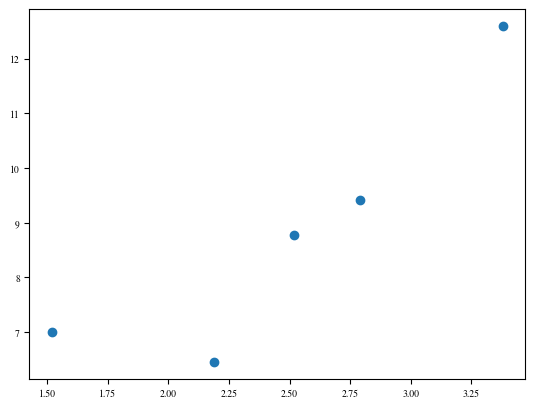

In [46]:
x = [2.79, 2.19, 2.52, 1.52, 3.38]
ys = [9.42, 6.45, 8.78, 7.00, 12.6]
yv = [1.31, 1.26, 1.54, 1.07, 1.45]

plt.scatter(x, ys)

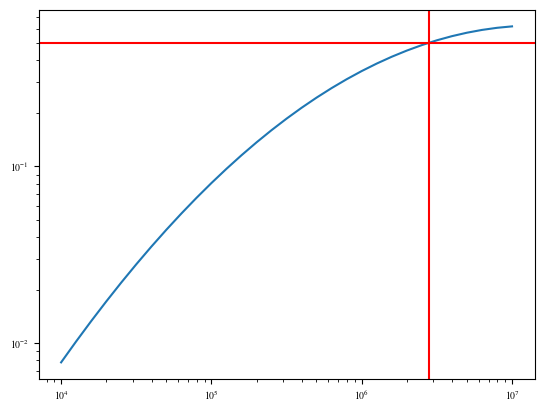

In [47]:
fn0_json = "../data/mw_gcs/fno_mw_gcs.json"
with open(fn0_json, "r") as f:
    fn0_dict = json.load(f)

xlogfit = np.arange(4, 7.1, 0.1)
A = fn0_dict["A"]
B = fn0_dict["B"]
C = fn0_dict["C"]

ylogfit = A + B * xlogfit + C * xlogfit**2
yerr = fn0_dict["yerr"]

plt.plot(10**xlogfit, 10**ylogfit)
plt.xscale("log")
plt.yscale("log")

# plt.axhline(0.1, c="r")
# plt.axvline(1.3 * 10**5, c="r")

plt.axhline(0.5, c="r")
plt.axvline(2.8 * 10**6, c="r")

# Mass Predictions

In [48]:
mass_lim = 1.3 * 10**5

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    lst = []
    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]

        smsk = src_dat["tdis"][()] != -1

        mfor = 10 ** src_dat["logm_tfor"][()]
        mmsk = mfor >= mass_lim

        rmsk = np.linalg.norm(src_dat["pxyz_snap600"], axis=1) < 3

        ages = src_dat["tdis"][smsk & mmsk & rmsk] - src_dat["tfor"][smsk & mmsk & rmsk]

        lst.append(np.mean(ages))

    print(sim, np.mean(lst))

m12b 4.291430981606885
m12c 6.720180572839115
m12f 5.138896384847567
m12i 5.933064699029563
m12m 6.996608741422376
